In [1]:
import scanpy as sc
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import numpy as np

sys.path.append("../../../mapqc/")
import mapqc
import plotting

In [2]:
%load_ext lab_black
%load_ext autoreload
%autoreload 2

In [3]:
sc.set_figure_params(figsize=(5, 5))

## Analysis on default mapping:

In [4]:
dir_results_normal_mapping = "../remappings/Sheppard_2020_kl1_sample_as_batch/"

In [5]:
adata_emb = sc.read_h5ad(
    f"{dir_results_normal_mapping}/combined_embedding_klweight_1.h5ad"
)

In [6]:
with open(f"{dir_results_normal_mapping}/mapqc_results_healthy.pkl", "rb") as inp:
    mapqc_results_healthy = pickle.load(inp)
with open(f"{dir_results_normal_mapping}/mapqc_results_disease.pkl", "rb") as inp:
    mapqc_results_disease = pickle.load(inp)

In [7]:
adata_full = sc.read_h5ad(
    "../../../../../../workspace/hlca_lisa.sikkema_malte.luecken/HLCA_reproducibility/data/d10_1101_2022_03_10_483747/HLCA_v1.1_full.h5ad",
    backed="r",
)

In [8]:
adata_emb.obs.dataset = adata_emb.obs.dataset.tolist()
adata_emb.obs.loc[
    adata_emb.obs.core_or_extension == "extension", "dataset"
] = "Sheppard_2020"

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


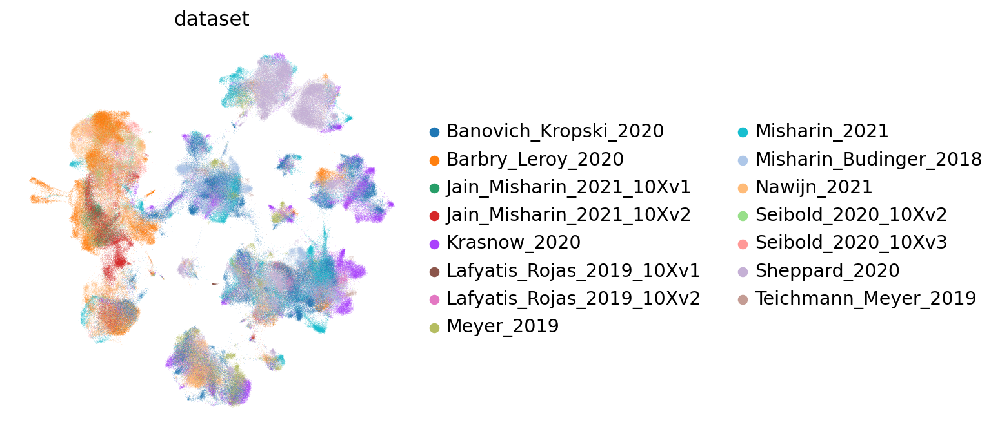

In [9]:
sc.pl.umap(adata_emb, color="dataset", frameon=False)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


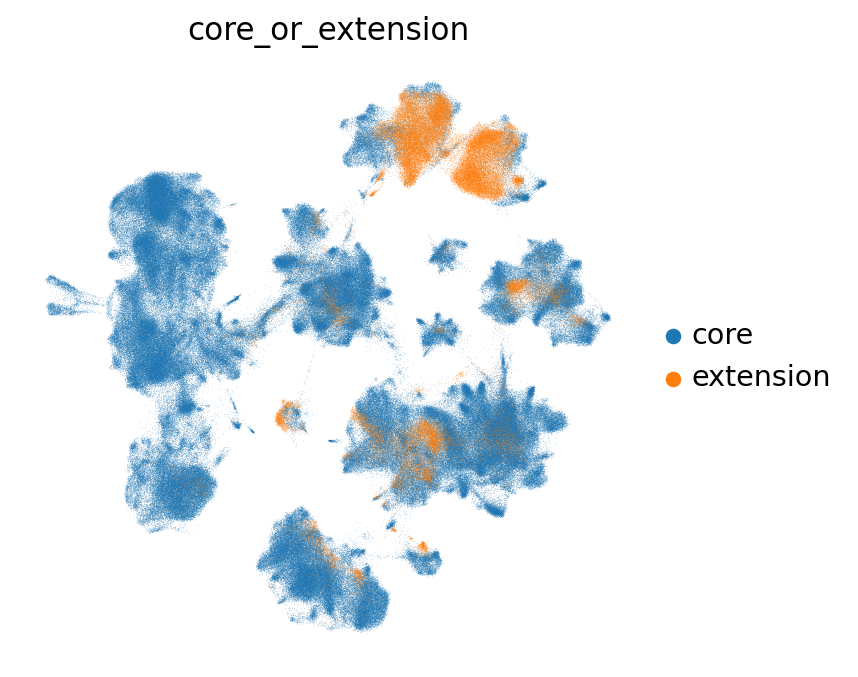

In [10]:
sc.pl.umap(adata_emb, color="core_or_extension", frameon=False)

In [11]:
palette_condition = {
    "reference": "tab:orange",
    "NML": "maroon",
    "IPF": "c",
    "SCD": "dodgerblue",
}

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


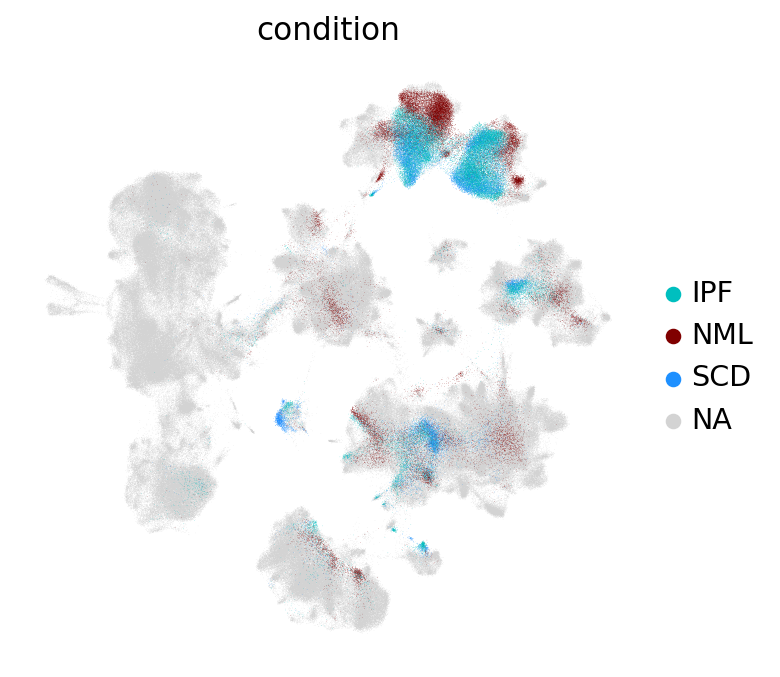

In [12]:
sc.pl.umap(adata_emb, color="condition", frameon=False, palette=palette_condition)

In [13]:
# sc.tl.leiden(adata_emb)

In [14]:
# clustering_df = pd.DataFrame(adata_emb.obs.leiden, index=adata_emb.obs.index)
# clustering_df.to_csv("./leiden_res_1_kl1_per_sample.csv")

load leiden clustering from previous run:

In [15]:
clustering_df = pd.read_csv("./leiden_res_1_kl1_per_sample.csv", index_col=0)

In [16]:
adata_emb.obs["leiden"] = pd.Categorical(
    clustering_df.loc[adata_emb.obs.index, "leiden"]
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


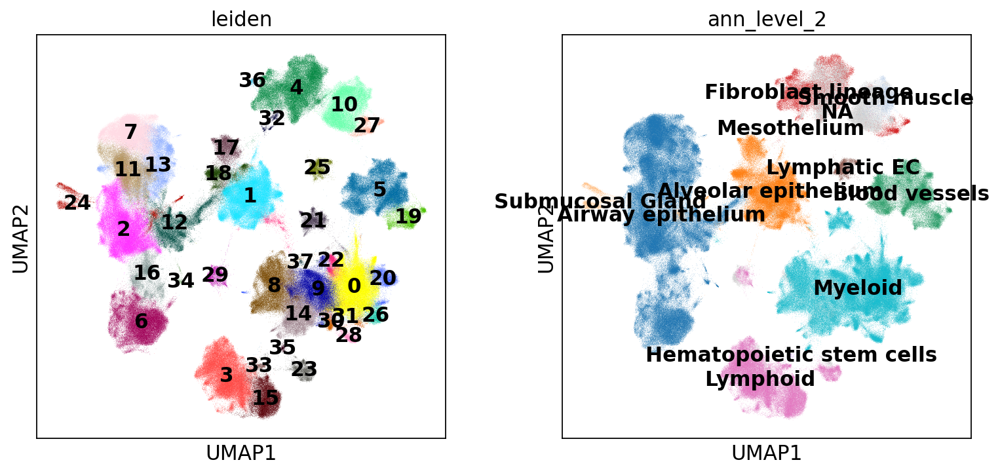

In [17]:
sc.pl.umap(adata_emb, color=["leiden", "ann_level_2"], legend_loc="on data")

In [18]:
adata_emb.obs.condition = adata_emb.obs.condition.tolist()
adata_emb.obs.condition = adata_emb.obs.condition.fillna(value="reference")

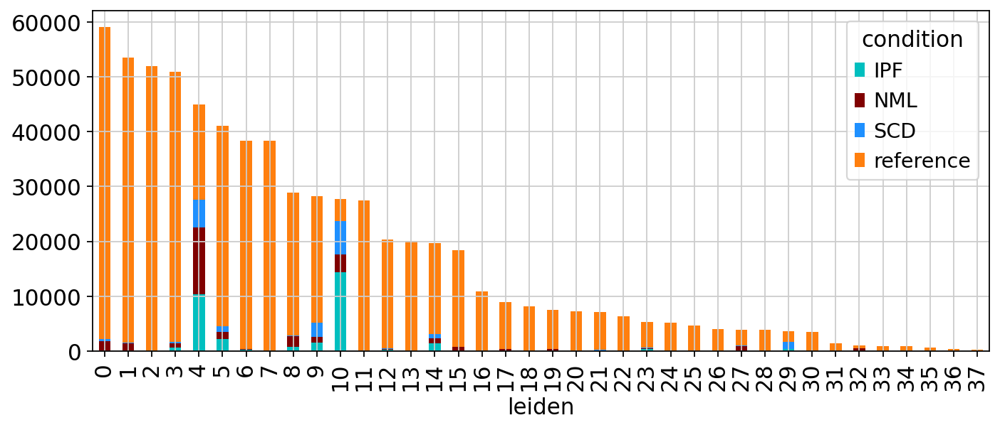

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
pd.crosstab(adata_emb.obs.leiden, adata_emb.obs.condition).plot(
    kind="bar", stacked=True, ax=ax, color=palette_condition
)
plt.tight_layout()

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


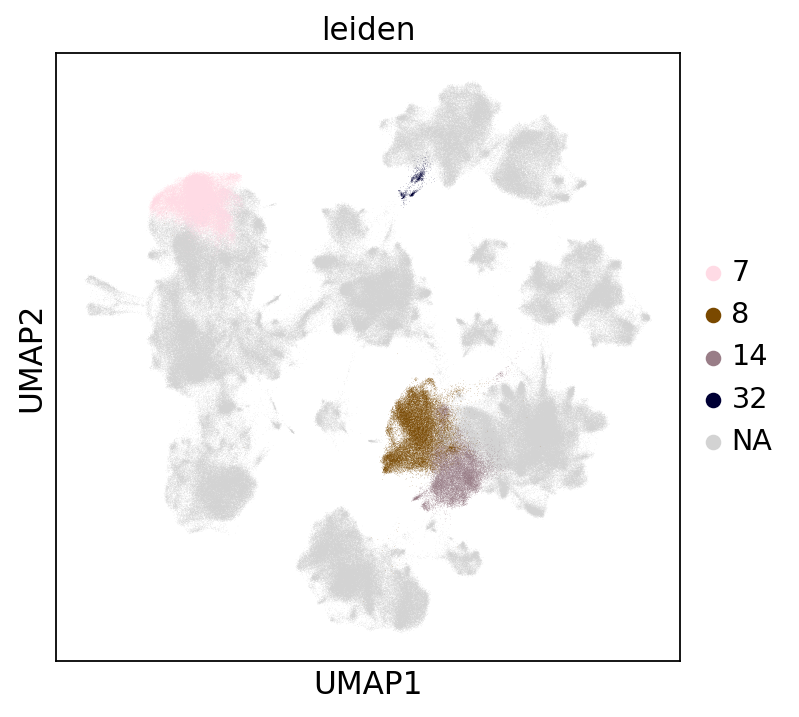

In [20]:
sc.pl.umap(adata_emb, color="leiden", groups=[7, 8, 14, 32])

In [21]:
adata_emb_cl16 = adata_emb[adata_emb.obs.leiden.isin([5, 19]), :].copy()

In [22]:
adata_emb_cl16.shape

(48576, 30)

In [23]:
sc.pp.neighbors(adata_emb_cl16, n_neighbors=30)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/umap/distances.py:1063: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/umap/distances.py:1071: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_o

In [24]:
sc.tl.umap(adata_emb_cl16)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


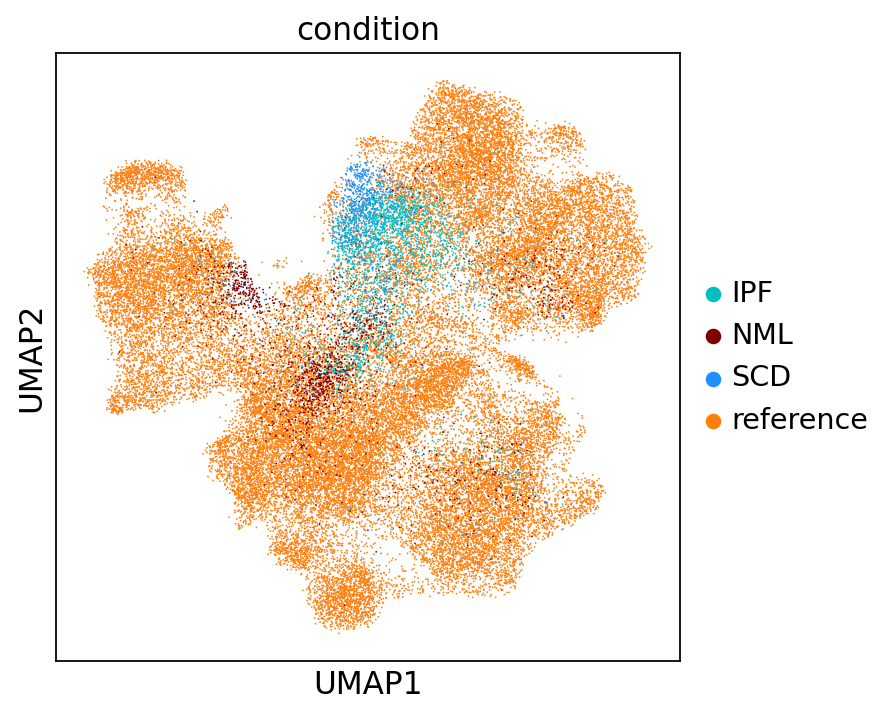

In [25]:
sc.pl.umap(adata_emb_cl16, color="condition", palette=palette_condition)

In [26]:
sc.tl.leiden(adata_emb_cl16, resolution=0.2)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


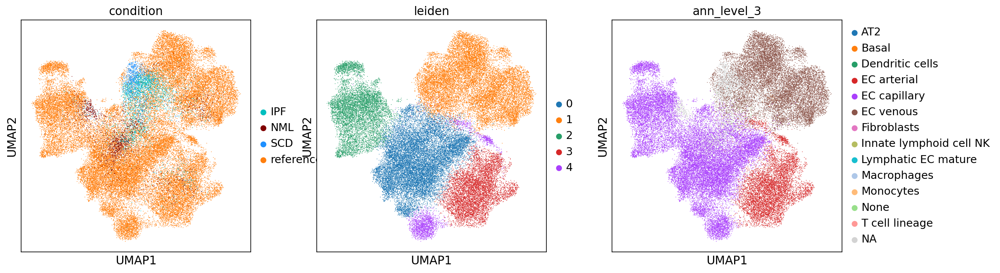

In [27]:
sc.pl.umap(adata_emb_cl16, color=["condition", "leiden", "ann_level_3"])

/tmp/ipykernel_2016428/867632577.py:9: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


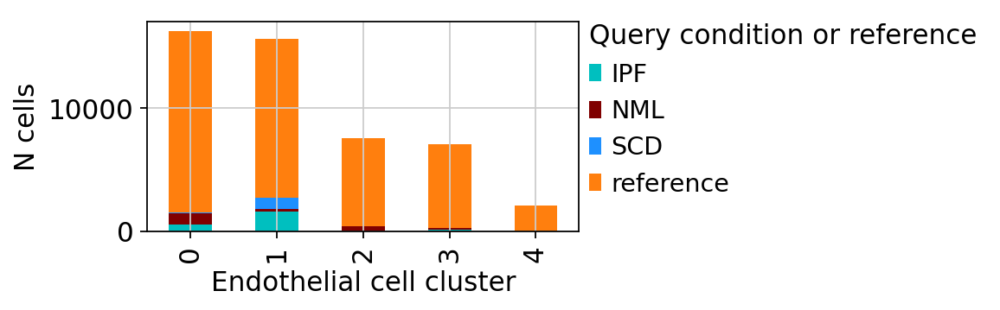

In [28]:
fig, ax = plt.subplots(figsize=(4, 2))
pd.crosstab(adata_emb_cl16.obs.leiden, adata_emb_cl16.obs.condition).plot(
    kind="bar", stacked="true", color=palette_condition, ax=ax
)
ax.set_ylabel("N cells")
ax.set_xlabel("Endothelial cell cluster")
leg = plt.legend(loc=(1.0, 0.12), frameon=False, title="Query condition or reference")
leg._legend_box.align = "left"
plt.tight_layout()

add tsukui suffix to Sheppard_2020 cells, so that barcodes correspond to barcodes in full HLCA:

In [29]:
adata_emb_cl16.obs.index = [
    idx if ref_or_q == "core" else f"{idx}_tsukui"
    for idx, ref_or_q in zip(
        adata_emb_cl16.obs.index, adata_emb_cl16.obs.core_or_extension
    )
]

In [30]:
adata_cl16 = adata_full[
    adata_full.obs.index.isin(adata_emb_cl16.obs.index), :
].to_memory()

In [31]:
adata_cl16.shape

(48576, 59586)

In [32]:
sc.pp.filter_genes(adata_cl16, min_cells=5)

In [33]:
adata_cl16.shape

(48576, 21492)

In [34]:
adata_cl16.X[-5:, -5:].toarray()

array([[1.7272943, 2.0716765, 0.       , 0.       , 0.       ],
       [0.       , 0.       , 0.       , 0.       , 0.       ],
       [0.       , 0.       , 0.       , 0.       , 0.       ],
       [0.       , 0.       , 0.       , 0.       , 0.       ],
       [0.       , 0.       , 0.       , 0.       , 0.       ]],
      dtype=float32)

In [35]:
adata_cl16.uns["log1p"]["base"] = None

In [36]:
adata_cl16.obsm["X_umap"] = adata_emb_cl16[adata_cl16.obs.index, :].obsm["X_umap"]

In [37]:
adata_cl16.obs["condition"] = adata_emb_cl16.obs.loc[adata_cl16.obs.index, "condition"]

In [38]:
adata_cl16.obs["leiden"] = adata_emb_cl16.obs.loc[adata_cl16.obs.index, "leiden"]

In [39]:
adata_cl16.obs.condition.value_counts()

reference    43668
IPF           2275
NML           1668
SCD            965
Name: condition, dtype: int64

In [40]:
adata_cl16.var.index = adata_cl16.var.gene_symbol

In [41]:
sc.tl.rank_genes_groups(adata_cl16, groupby="leiden")

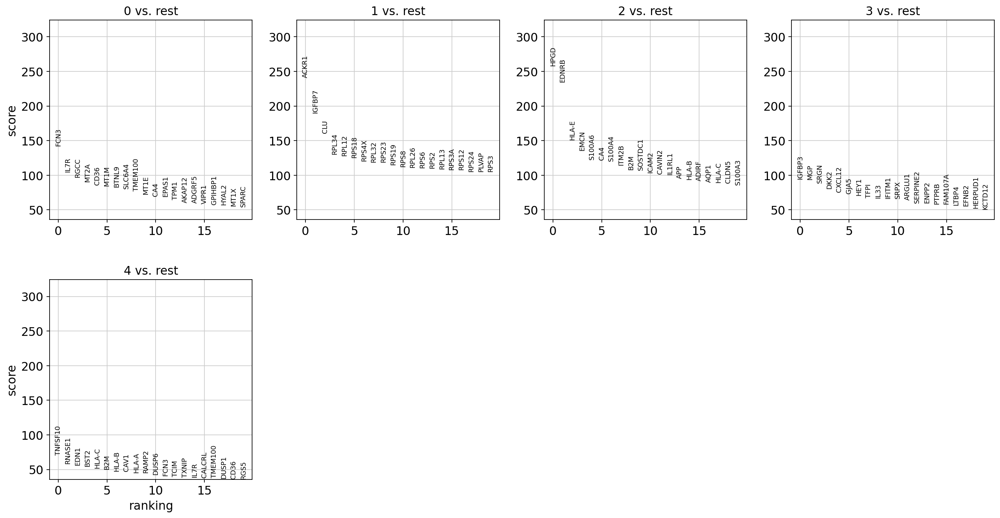

In [42]:
sc.pl.rank_genes_groups(adata_cl16)

In [44]:
gene_ids_used_during_mapping = pd.read_csv(
    "../remappings/HLCA_reference_model/var_names.csv", index_col=0
)

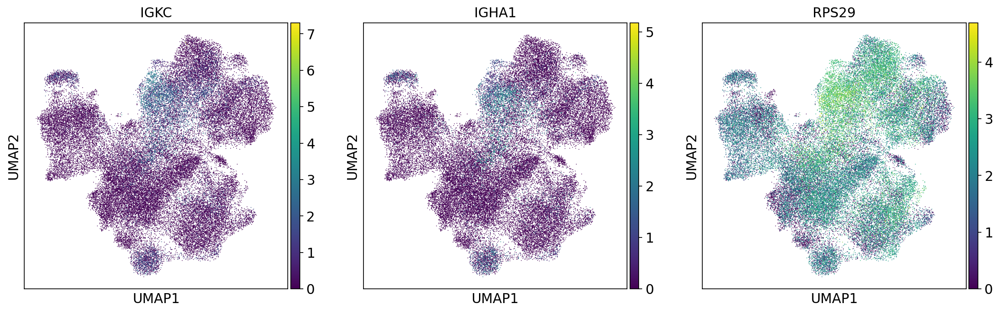

In [45]:
sc.pl.umap(adata_cl16, color=["IGKC", "IGHA1", "RPS29"])

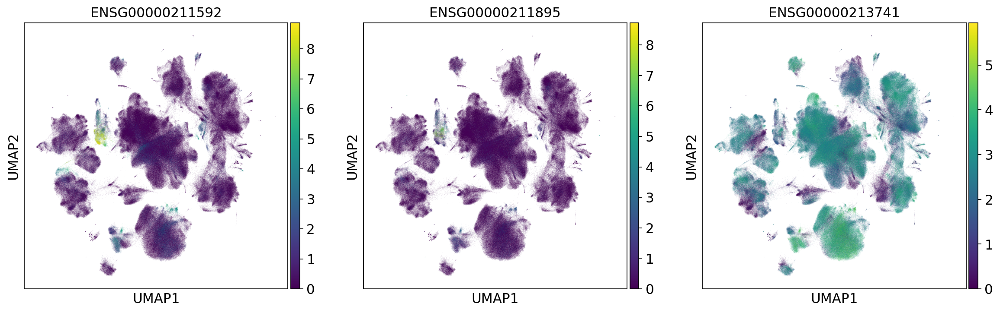

In [46]:
sc.pl.umap(
    adata_full,
    color=[
        adata_cl16.var.loc[gene_name, "ensembl_id"]
        for gene_name in ["IGKC", "IGHA1", "RPS29"]
    ],
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


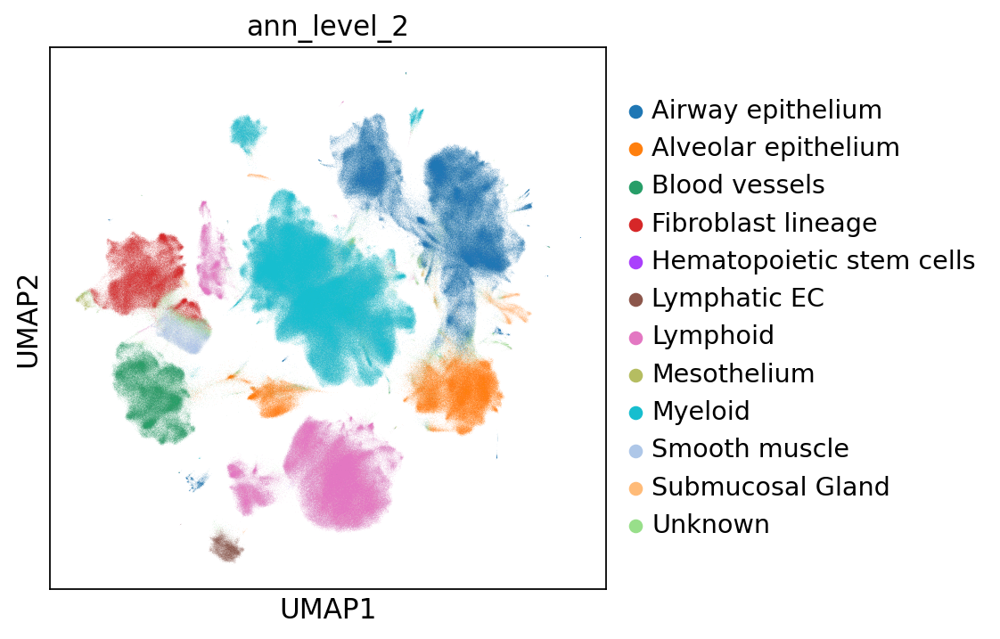

In [47]:
sc.pl.umap(adata_full, color="ann_level_2")

In [48]:
mapqc_results_healthy._adata_prepped_for_cell_level_res_plotting_sample_based = False
mapqc_results_healthy._adata_prepped_for_cell_level_res_plotting_nhood_only_based = (
    False
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


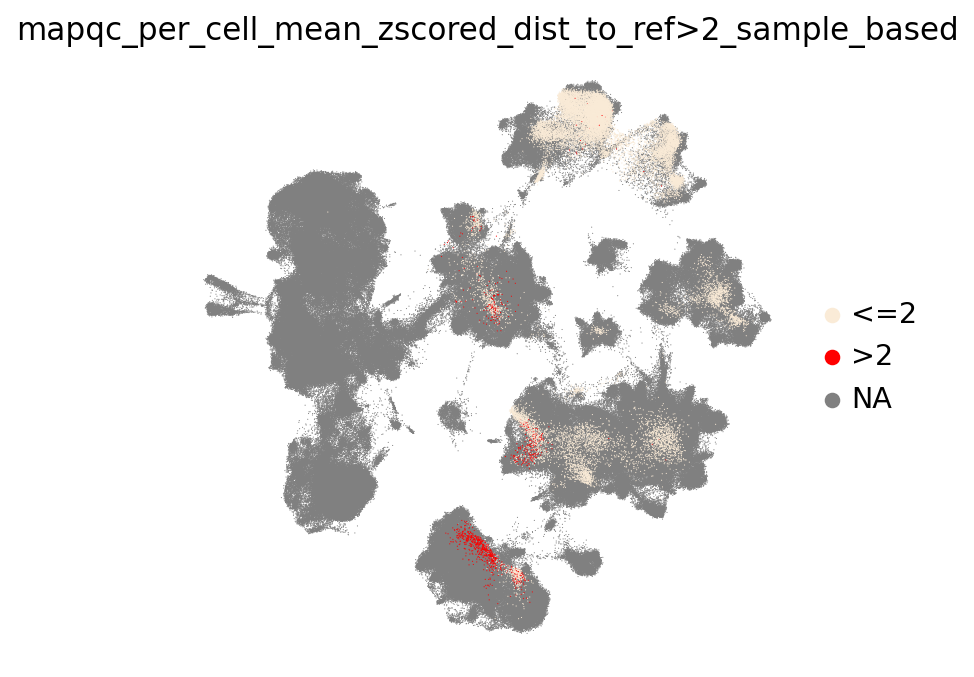

In [49]:
plotting.plot_umap_cell_level_results(
    mapqc_results_healthy, color_by="zscore>2", size=1
)

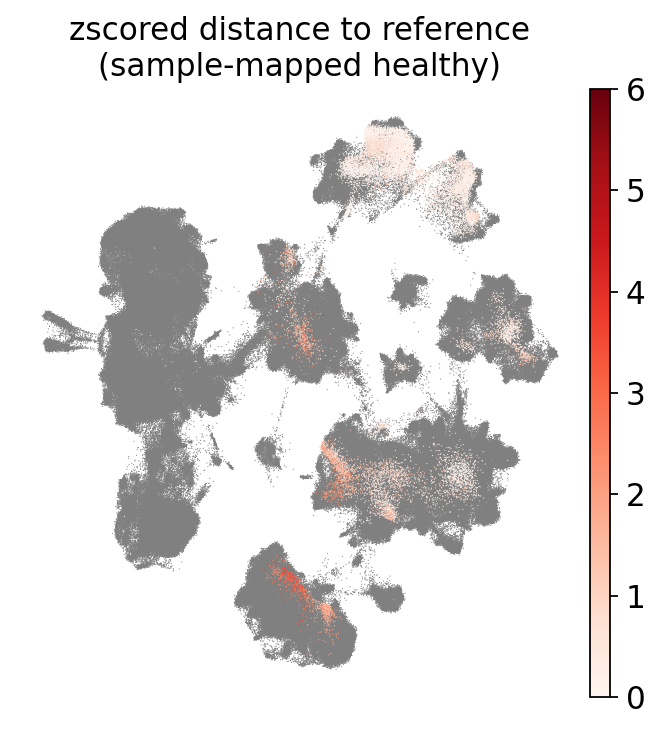

In [50]:
plotting.plot_umap_cell_level_results(
    mapqc_results_healthy,
    color_by="zscore",
    size=1,
    vmin=0,
    vmax=6,
    title="zscored distance to reference\n(sample-mapped healthy)",
)

## mapQC results disease:

In [51]:
mapqc_results_disease._adata_prepped_for_cell_level_res_plotting_sample_based = False
mapqc_results_disease._adata_prepped_for_cell_level_res_plotting_nhood_only_based = (
    False
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


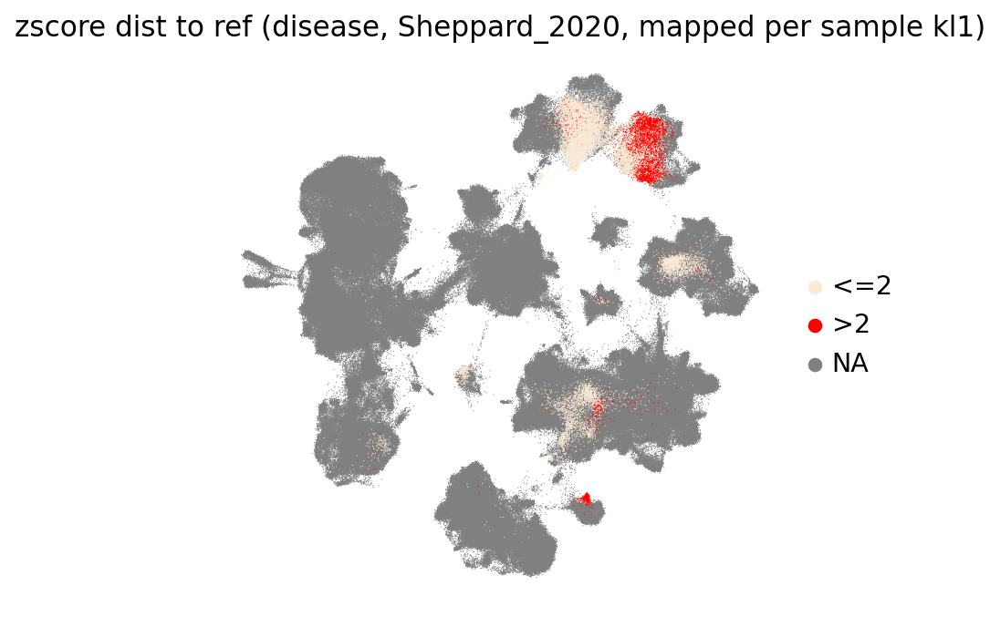

In [52]:
plotting.plot_umap_cell_level_results(
    mapqc_results_disease,
    color_by="zscore>2",
    size=1,
    title="zscore dist to ref (disease, Sheppard_2020, mapped per sample kl1)",
)

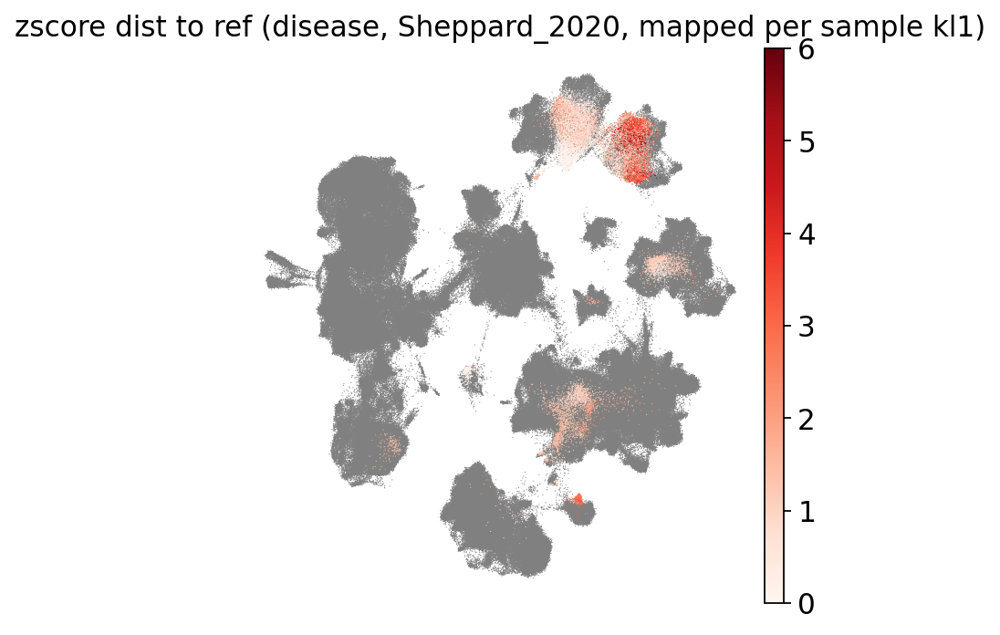

In [53]:
plotting.plot_umap_cell_level_results(
    mapqc_results_disease,
    color_by="zscore",
    size=1,
    vmin=0,
    vmax=6,
    title="zscore dist to ref (disease, Sheppard_2020, mapped per sample kl1)",
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


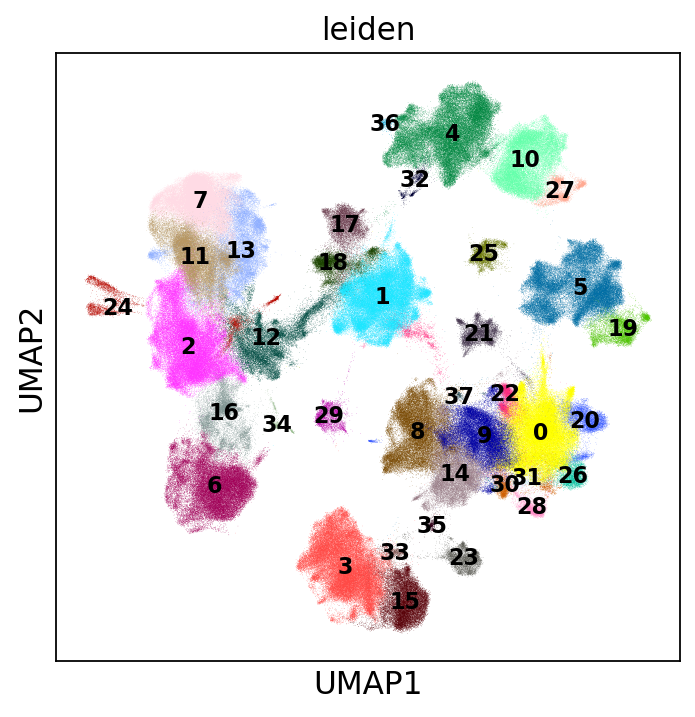

In [54]:
sc.pl.umap(
    adata_emb, color=["leiden"], legend_loc="on data", legend_fontsize=10, ncols=1
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


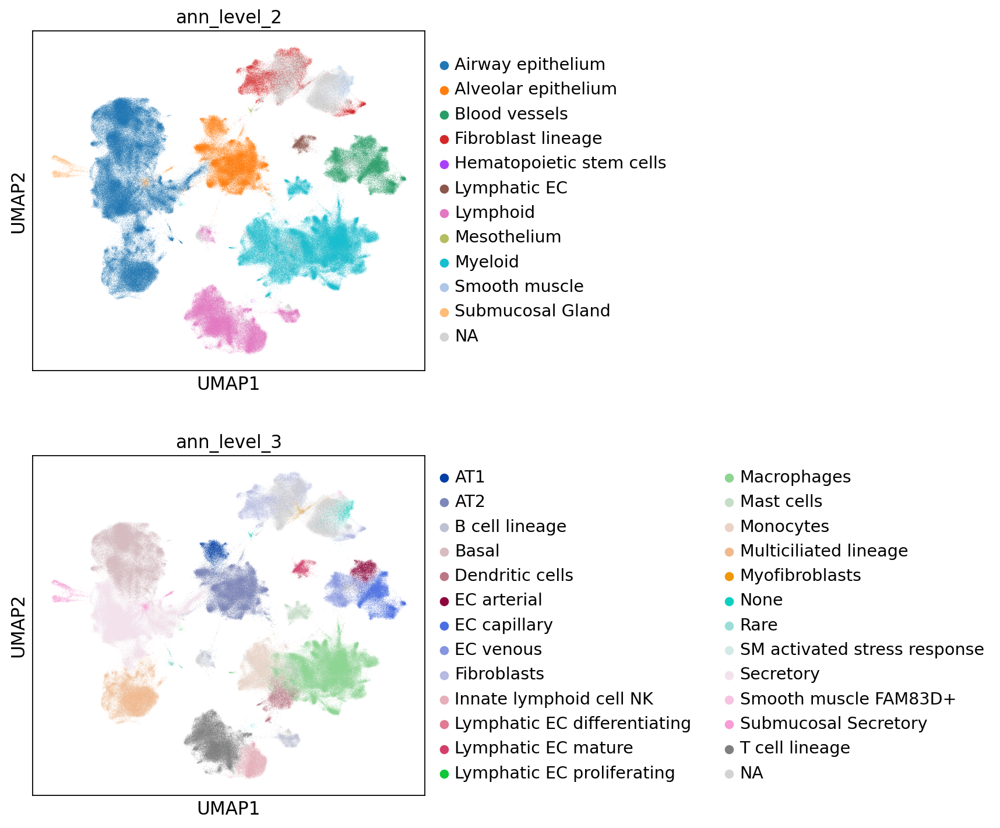

In [55]:
sc.pl.umap(adata_emb, color=["ann_level_2", "ann_level_3"], ncols=1)

In [56]:
sm_dis_emb = adata_emb[adata_emb.obs.leiden.isin([10, 27]), :].copy()

In [57]:
sm_dis_emb.obs.leiden.value_counts()

10    27704
27     3935
Name: leiden, dtype: int64

In [58]:
sm_dis_emb.shape

(31639, 30)

In [59]:
sm_dis_emb.obs.condition.value_counts()

IPF          14463
reference     6990
SCD           6062
NML           4124
Name: condition, dtype: int64

In [60]:
for stat in [
    "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
]:
    sm_dis_emb.obs[stat] = np.nan
    healthy_idc = [
        idx
        for idx in sm_dis_emb.obs.index
        if idx in mapqc_results_healthy.adata.obs.index
    ]
    sm_dis_emb.obs.loc[healthy_idc, stat] = mapqc_results_healthy.adata.obs.loc[
        healthy_idc, stat
    ]
    disease_idc = [
        idx
        for idx in sm_dis_emb.obs.index
        if idx in mapqc_results_disease.adata.obs.index
    ]
    sm_dis_emb.obs.loc[disease_idc, stat] = mapqc_results_disease.adata.obs.loc[
        disease_idc, stat
    ]

In [61]:
sc.pp.neighbors(sm_dis_emb, n_neighbors=30)

In [62]:
sc.tl.umap(sm_dis_emb)

In [63]:
sc.tl.leiden(sm_dis_emb, resolution=0.5)

/tmp/ipykernel_2016428/1071351919.py:9: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


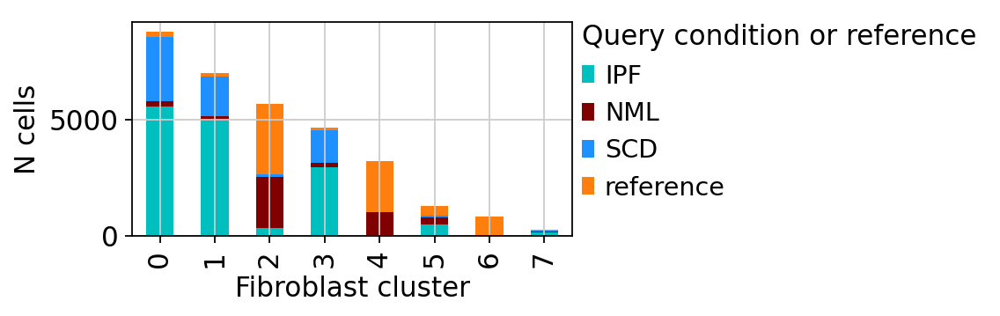

In [64]:
fig, ax = plt.subplots(figsize=(4, 2))
pd.crosstab(sm_dis_emb.obs.leiden, sm_dis_emb.obs.condition).plot(
    kind="bar", stacked="true", color=palette_condition, ax=ax
)
ax.set_ylabel("N cells")
ax.set_xlabel("Fibroblast cluster")
leg = plt.legend(loc=(1.0, 0.12), frameon=False, title="Query condition or reference")
leg._legend_box.align = "left"
plt.tight_layout()

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/

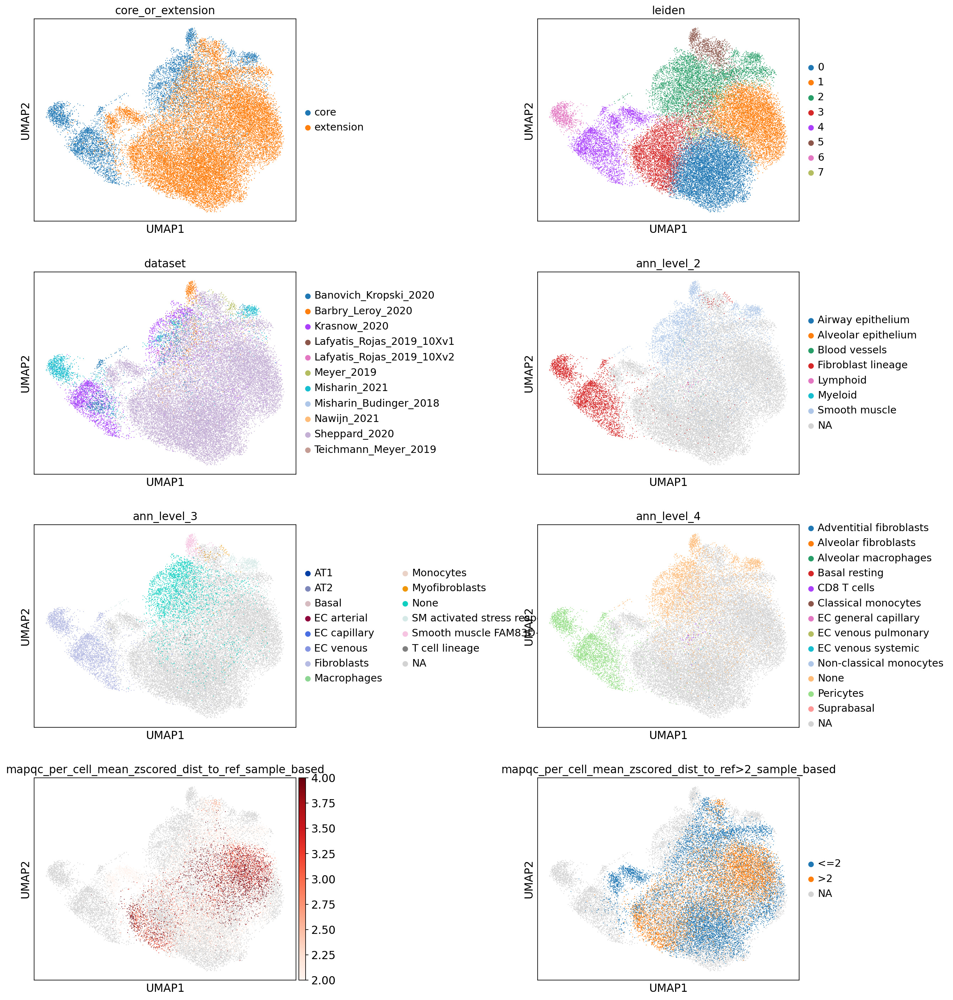

In [65]:
sc.pl.umap(
    sm_dis_emb,
    color=[
        "core_or_extension",
        "leiden",
        "dataset",
        "ann_level_2",
        "ann_level_3",
        "ann_level_4",
        "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
        "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
    ],
    ncols=2,
    wspace=0.75,
    vmin=2,
    vmax=4,
    cmap="Reds",
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


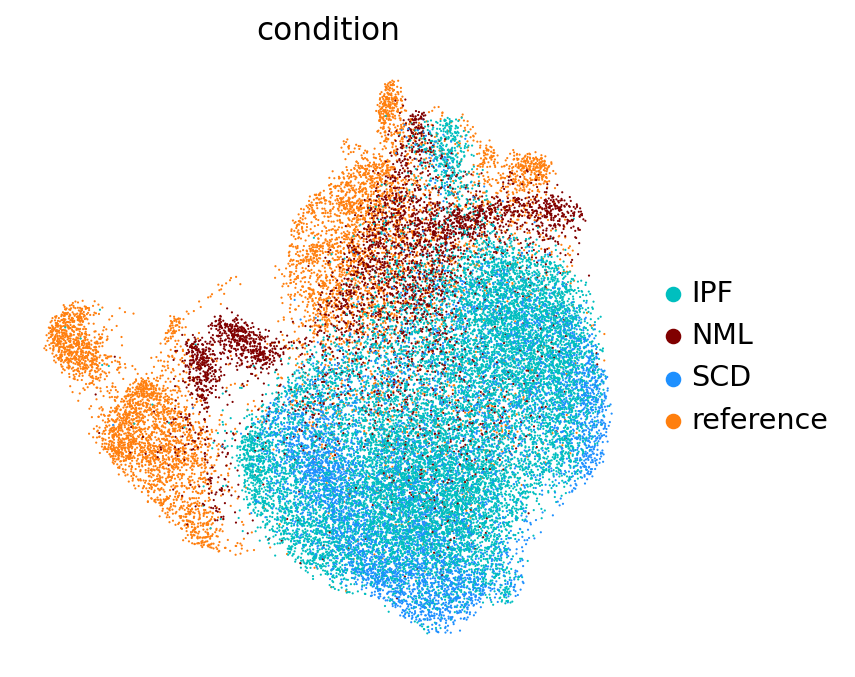

In [66]:
sc.pl.umap(sm_dis_emb, color="condition", palette=palette_condition, frameon=False)

In [67]:
sm_dis_emb.obs.index = [
    idx if ref_or_q == "core" else f"{idx}_tsukui"
    for idx, ref_or_q in zip(sm_dis_emb.obs.index, sm_dis_emb.obs.core_or_extension)
]

In [68]:
adata_sm_dis = adata_full[
    adata_full.obs.index.isin(sm_dis_emb.obs.index), :
].to_memory()

In [69]:
sm_dis_emb.shape

(31639, 30)

In [70]:
adata_sm_dis.shape

(31639, 59586)

In [71]:
sc.pp.filter_genes(adata_sm_dis, min_cells=5)

In [72]:
adata_sm_dis.shape

(31639, 20150)

In [73]:
adata_sm_dis.X[-10:, -10:].toarray()

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.41327816, 0.        ,
        0.41327816, 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [1.3120508 , 0.        , 0.        , 1.3120508 , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.       

In [74]:
adata_sm_dis.uns["log1p"]["base"] = None

In [75]:
adata_sm_dis.obsm["X_umap"] = sm_dis_emb[adata_sm_dis.obs.index, :].obsm["X_umap"]

In [76]:
for cat in [
    "condition",
    "leiden",
    "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
]:
    adata_sm_dis.obs[cat] = sm_dis_emb.obs.loc[adata_sm_dis.obs.index, cat]

In [77]:
adata_sm_dis.obs.condition.value_counts()

IPF          14463
reference     6990
SCD           6062
NML           4124
Name: condition, dtype: int64

In [78]:
adata_sm_dis.var.index = adata_sm_dis.var.gene_symbol

plot pericyte and smooth muscle markers:

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


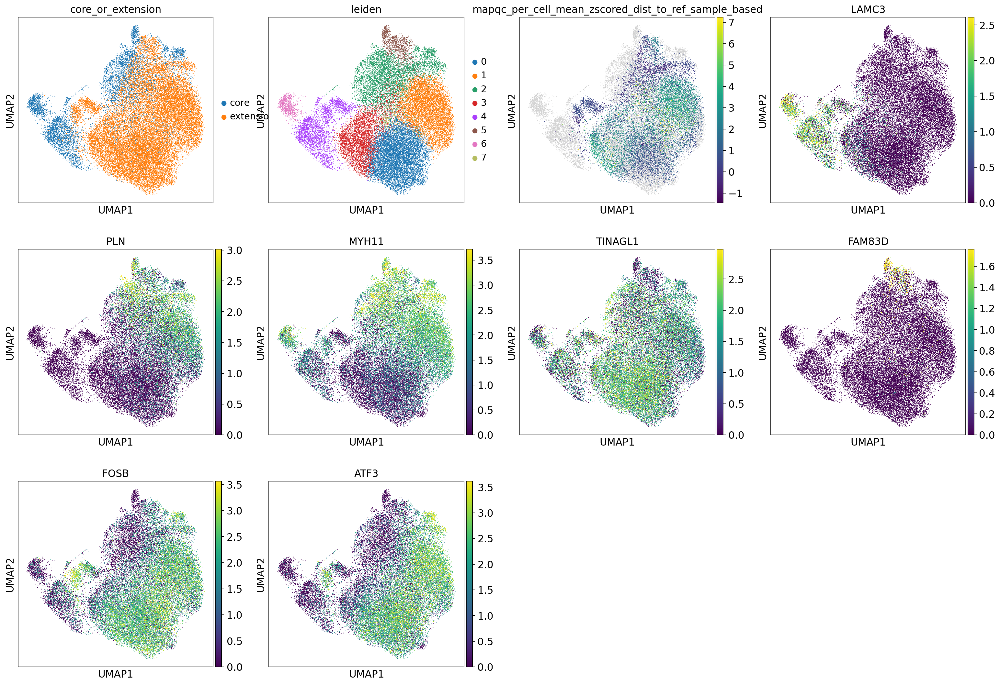

In [79]:
sc.pl.umap(
    adata_sm_dis,
    color=[
        "core_or_extension",
        "leiden",
        "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
        "LAMC3",  # pericytes
        "PLN",  # smooth muscle, not pericytes
        "MYH11",  # smooth muscle, some in pericytes
        "TINAGL1",  # smooth muscle, some in pericytes
        "FAM83D",  # FAM83D+ sm
        "FOSB",  # SM stress
        "ATF3",  # SM stress
        # "KLK11",  # mesothelium
        # "LUM",  # fibroblasts
        # "COL6A3",  # fibroblasts
        # "CXCL14",  # peribronch. fibs.
        # "SCARA5",  # adv. fibs.
        # "SPINT2",  # alv. fibs.
        # "LIMCH1",  # alv. fibs.
        # "MARCKSL1",  # subpl. fibs.
        # "APOC1",  # subpl. fibs.
        # "MMP23B",  # subpl. fibs
        # "TYRP1",  # myofibroblasts, some in sm FAM83D+
    ],
    vmax="p99",
)

check which clusters have a lot of disease, and/or which clusters have high mapQC scores:

/tmp/ipykernel_2016428/1146595797.py:9: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


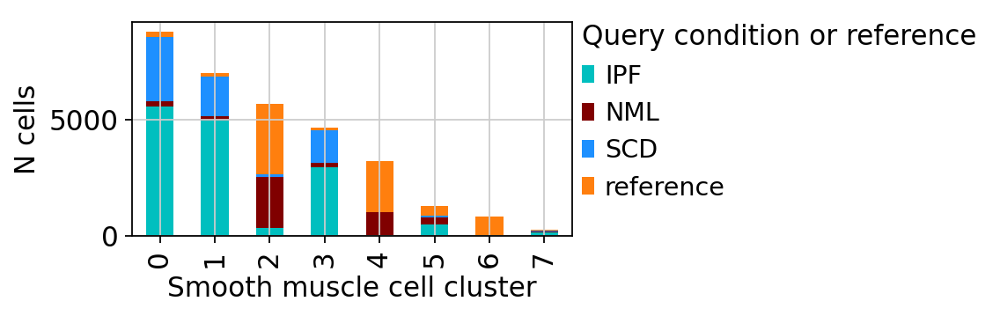

In [80]:
fig, ax = plt.subplots(figsize=(4, 2))
pd.crosstab(sm_dis_emb.obs.leiden, sm_dis_emb.obs.condition).plot(
    kind="bar", stacked="true", color=palette_condition, ax=ax
)
ax.set_ylabel("N cells")
ax.set_xlabel("Smooth muscle cell cluster")
leg = plt.legend(loc=(1.0, 0.12), frameon=False, title="Query condition or reference")
leg._legend_box.align = "left"
plt.tight_layout()

In [81]:
df_to_plot = sm_dis_emb.obs.loc[
    :, ["leiden", "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based"]
].dropna(axis=0, how="any")
df_to_plot.leiden = df_to_plot.leiden.astype(str)
df_to_plot.mapqc_per_cell_mean_zscored_dist_to_ref_sample_based = (
    df_to_plot.mapqc_per_cell_mean_zscored_dist_to_ref_sample_based.astype(float)
)

<Axes: xlabel='leiden', ylabel='mapqc_per_cell_mean_zscored_dist_to_ref_sample_based'>

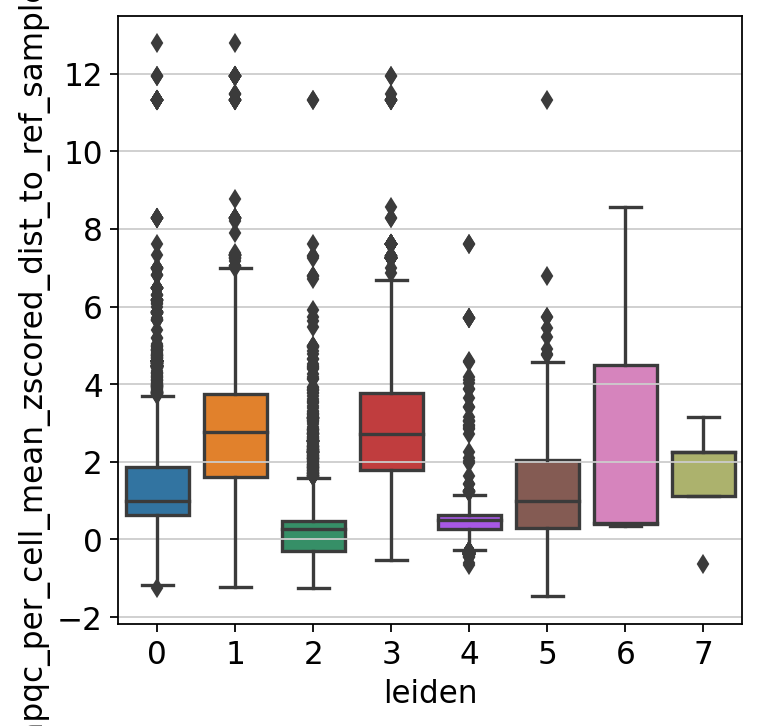

In [82]:
sns.boxplot(
    df_to_plot,
    x="leiden",
    y="mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    order=sorted(df_to_plot.leiden.unique()),
)

fibroblast/sm markers

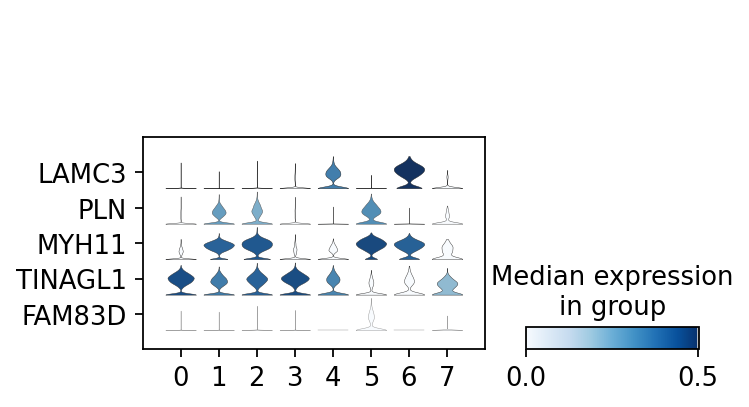

In [83]:
sc.pl.stacked_violin(
    adata_sm_dis,
    groupby="leiden",
    var_names=["LAMC3", "PLN", "MYH11", "TINAGL1", "FAM83D"],
    swap_axes=True,
    standard_scale="var",
)

do diff. exp. analysis on perictyes specifically

In [84]:
adata_sm_dis.obs["sm_clusters"] = adata_sm_dis.obs.leiden.map(
    {
        "0": "other",
        "1": "sm_abnormal",
        "2": "sm_normal",
        "3": "other",
        "4": "other",
        "5": "sm_normal",
        "6": "other",
        "7": "other",
    }
)

In [85]:
sc.tl.rank_genes_groups(
    adata_sm_dis,
    groupby="sm_clusters",
    groups=["sm_abnormal"],
    reference="sm_normal",
)

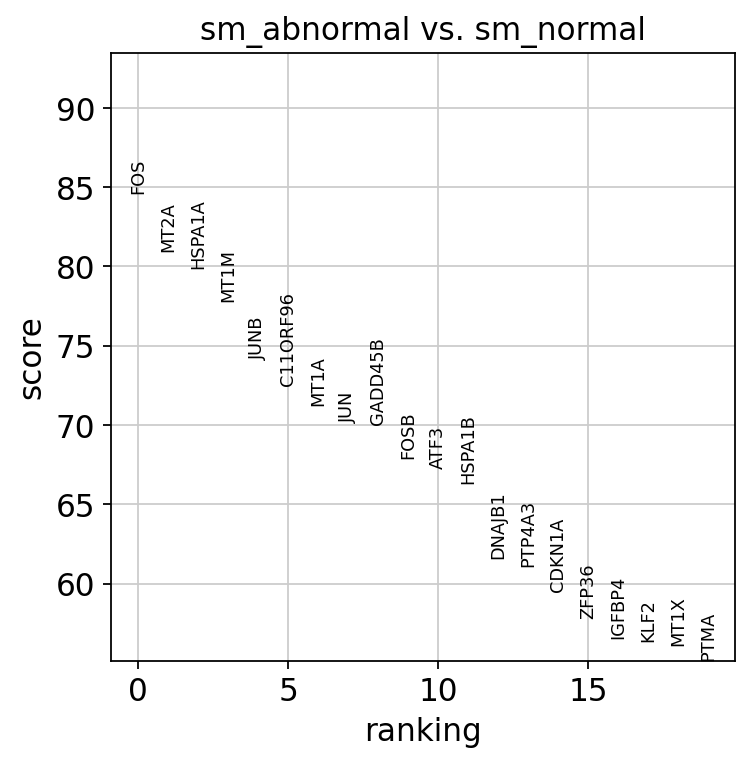

In [86]:
sc.pl.rank_genes_groups(adata_sm_dis)

In [87]:
degs_pericyte_cluster = sc.get.rank_genes_groups_df(adata_sm_dis, group="sm_abnormal")

In [88]:
genes_in_data_used_during_mapping = adata_sm_dis.var.loc[
    adata_sm_dis.var.ensembl_id.isin(gene_ids_used_during_mapping.index), :
].index.tolist()

In [89]:
degs_perictye_cluster_used_during_mapping = degs_pericyte_cluster.loc[
    degs_pericyte_cluster.names.isin(genes_in_data_used_during_mapping), :
]

In [90]:
adata_sm_only = adata_sm_dis[adata_sm_dis.obs.sm_clusters != "other", :].copy()
adata_sm_only_query_only = adata_sm_only[
    ~pd.isnull(adata_sm_only.obs.mapqc_per_cell_mean_zscored_dist_to_ref_sample_based),
    :,
].copy()

In [91]:
sc.pp.filter_genes(adata_sm_only_query_only, min_cells=50)

In [92]:
from scipy.stats import pearsonr

In [93]:
4 % 2

0

In [94]:
corrs = pd.DataFrame(index=adata_sm_only_query_only.var.index, columns=["r", "p"])
dist_to_ref_zscores = (
    adata_sm_only_query_only.obs.mapqc_per_cell_mean_zscored_dist_to_ref_sample_based.values
)
for i in range(adata_sm_only_query_only.shape[1]):
    if i % 500 == 0:
        print(i)
    corrs.iloc[i, :] = pearsonr(
        np.ravel(adata_sm_only_query_only.X[:, i].toarray()), dist_to_ref_zscores
    )

0
500
1000
1500
2000
2500
3000
3500
4000
4500
5000
5500
6000
6500
7000
7500
8000
8500
9000
9500
10000
10500
11000


In [95]:
corrs_sorted = corrs.dropna(axis=0, how="any").sort_values(by="r")

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


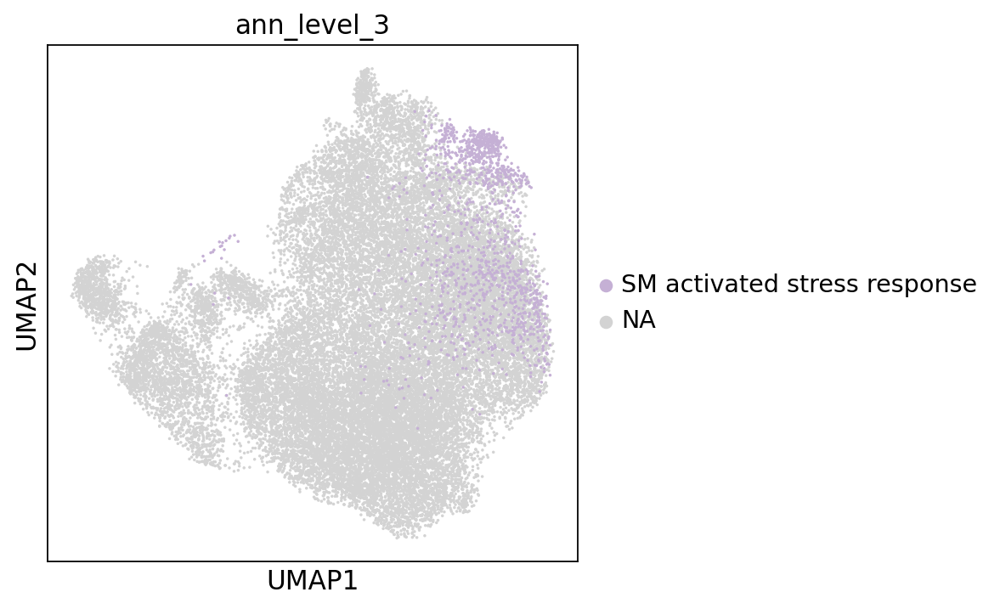

In [96]:
sc.pl.umap(
    adata_sm_dis, color="ann_level_3", groups="SM activated stress response", size=10
)

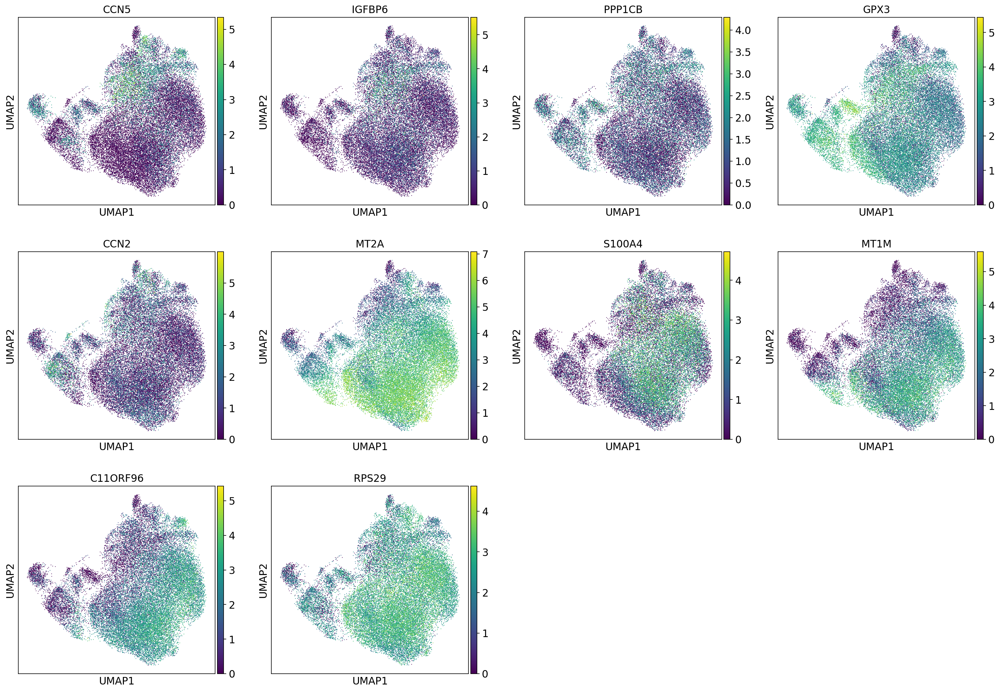

In [97]:
sc.pl.umap(
    adata_sm_dis,
    color=corrs_sorted.index[:5].tolist() + corrs_sorted.index[-5:].tolist(),
)

In [98]:
adata_sm_dis.obs.ann_level_2.value_counts()

Smooth muscle          19464
Fibroblast lineage      6252
Unknown                 5811
Lymphoid                  60
Myeloid                   28
Blood vessels             20
Airway epithelium          2
Alveolar epithelium        2
Name: ann_level_2, dtype: int64

In [99]:
(adata_sm_dis.obs.core_or_extension == "core") & (
    adata_sm_dis.obs.ann_level_3 == "SM activated stress response"
)

CGCGTTTTCGGTTAAC_IPF1_tsukui    False
CATCCACGTCCATCCT_IPF1_tsukui    False
AAACGGGAGTGGGATC_IPF2_tsukui    False
CACCTTGCAAGCCATT_NML2_tsukui    False
GGTTCTCGTTCCGGTG_SC86           False
                                ...  
CCATTCGTCATGTGGT_IPF3_tsukui    False
P2_5_AAGTCTGCAACTGCTA           False
GTACTCCTCATCGGAT_NML1_tsukui    False
P3_4_TAAACCGGTGTCCTCT           False
P3_4_GCTTGAACACGACGAA           False
Length: 31639, dtype: bool

In [100]:
adata_sm_dis.obs.ann_level_3.value_counts()

Unknown                         12867
Fibroblasts                      6030
None                             2937
SM activated stress response     1388
Smooth muscle FAM83D+             376
Myofibroblasts                    138
T cell lineage                     51
Macrophages                         8
EC venous                           7
EC capillary                        6
Monocytes                           6
B cell lineage                      4
Basal                               2
Dendritic cells                     1
EC arterial                         1
AT2                                 1
AT1                                 1
Name: ann_level_3, dtype: int64

In [101]:
adata_sm_dis.obs["sm_group"] = None
adata_sm_dis.obs.loc[
    adata_sm_dis.obs.core_or_extension == "core",
    "sm_group",
] = "reference (other)"
adata_sm_dis.obs.loc[
    (adata_sm_dis.obs.core_or_extension == "core")
    & (adata_sm_dis.obs.ann_level_3 == "SM activated stress response"),
    "sm_group",
] = "reference (SM activated)"
adata_sm_dis.obs.loc[
    (adata_sm_dis.obs.core_or_extension == "core")
    & (adata_sm_dis.obs.ann_level_3 == "Smooth muscle FAM83D+"),
    "sm_group",
] = "reference (SM FAM83D+)"

adata_sm_dis.obs.loc[adata_sm_dis.obs.condition == "NML", "sm_group"] = "query control"
adata_sm_dis.obs.loc[
    adata_sm_dis.obs["mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based"] == "<=2",
    "sm_group",
] = "query disease, normal dist. to ref."
adata_sm_dis.obs.loc[
    adata_sm_dis.obs["mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based"] == ">2",
    "sm_group",
] = "query disease, large dist. to ref."

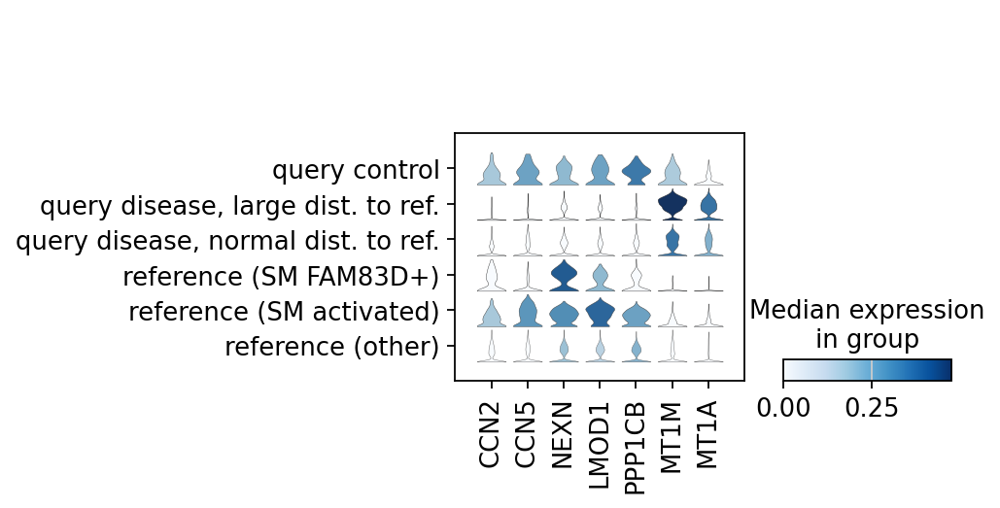

In [102]:
sc.pl.stacked_violin(
    adata_sm_dis,
    groupby="sm_group",
    var_names=["CCN2", "CCN5", "NEXN", "LMOD1", "PPP1CB", "MT1M", "MT1A"],
    standard_scale="var",
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:749: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


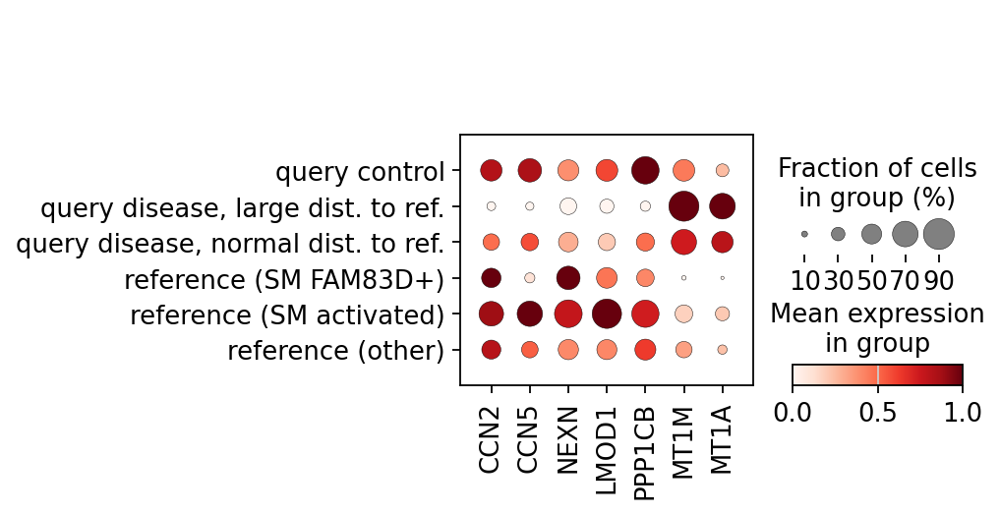

In [103]:
sc.pl.dotplot(
    adata_sm_dis,
    groupby="sm_group",
    var_names=["CCN2", "CCN5", "NEXN", "LMOD1", "PPP1CB", "MT1M", "MT1A"],
    standard_scale="var",
)

In [104]:
adata_sm_dis.obs["mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based"]

CGCGTTTTCGGTTAAC_IPF1_tsukui    <=2
CATCCACGTCCATCCT_IPF1_tsukui    <=2
AAACGGGAGTGGGATC_IPF2_tsukui    <=2
CACCTTGCAAGCCATT_NML2_tsukui    <=2
GGTTCTCGTTCCGGTG_SC86           NaN
                               ... 
CCATTCGTCATGTGGT_IPF3_tsukui     >2
P2_5_AAGTCTGCAACTGCTA           NaN
GTACTCCTCATCGGAT_NML1_tsukui    <=2
P3_4_TAAACCGGTGTCCTCT           NaN
P3_4_GCTTGAACACGACGAA           NaN
Name: mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based, Length: 31639, dtype: category
Categories (2, object): ['<=2', '>2']

In [105]:
test = pd.crosstab(adata_sm_dis.obs.sm_clusters, adata_sm_dis.obs["sample"])

In [106]:
test.loc["sm_abnormal", :].sort_values()[-10:]

sample
NML2_Lin      35
NML3_Lin      58
IPF2_All      73
NML1_Lin      92
SCD2_Lin     221
IPF3_All     363
IPF2_Lin     564
IPF1_Lin     911
SCD1_Lin    1450
IPF3_Lin    3023
Name: sm_abnormal, dtype: int64

/tmp/ipykernel_2016428/407698584.py:4: FutureWarning: The behavior of `series[i:j]` with an integer-dtype index is deprecated. In a future version, this will be treated as *label-based* indexing, consistent with e.g. `series[i]` lookups. To retain the old behavior, use `series.iloc[i:j]`. To get the future behavior, use `series.loc[i:j]`.
  + degs_perictye_cluster_used_during_mapping.names[:10].tolist(),
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No da

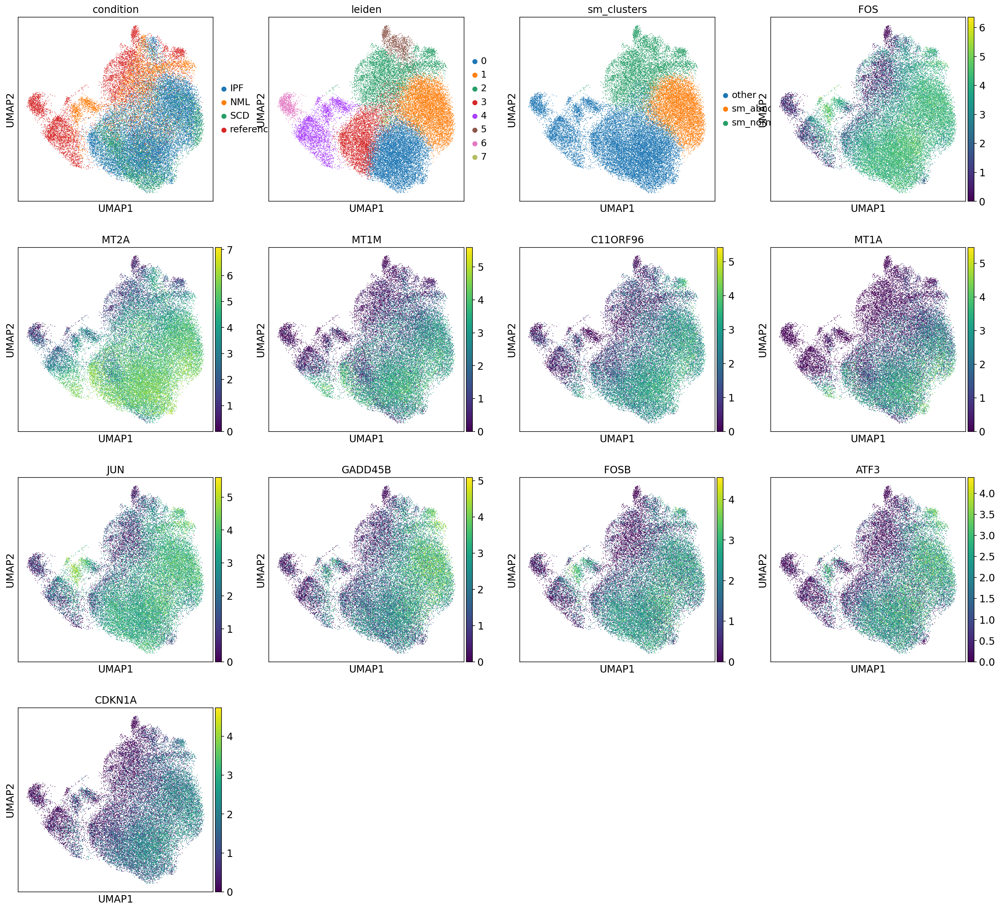

In [107]:
sc.pl.umap(
    adata_sm_dis,
    color=["condition", "leiden", "sm_clusters"]
    + degs_perictye_cluster_used_during_mapping.names[:10].tolist(),
)

/tmp/ipykernel_2016428/810902958.py:4: FutureWarning: The behavior of `series[i:j]` with an integer-dtype index is deprecated. In a future version, this will be treated as *label-based* indexing, consistent with e.g. `series[i]` lookups. To retain the old behavior, use `series.iloc[i:j]`. To get the future behavior, use `series.loc[i:j]`.
  + degs_perictye_cluster_used_during_mapping.names[-10:].tolist(),
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No d

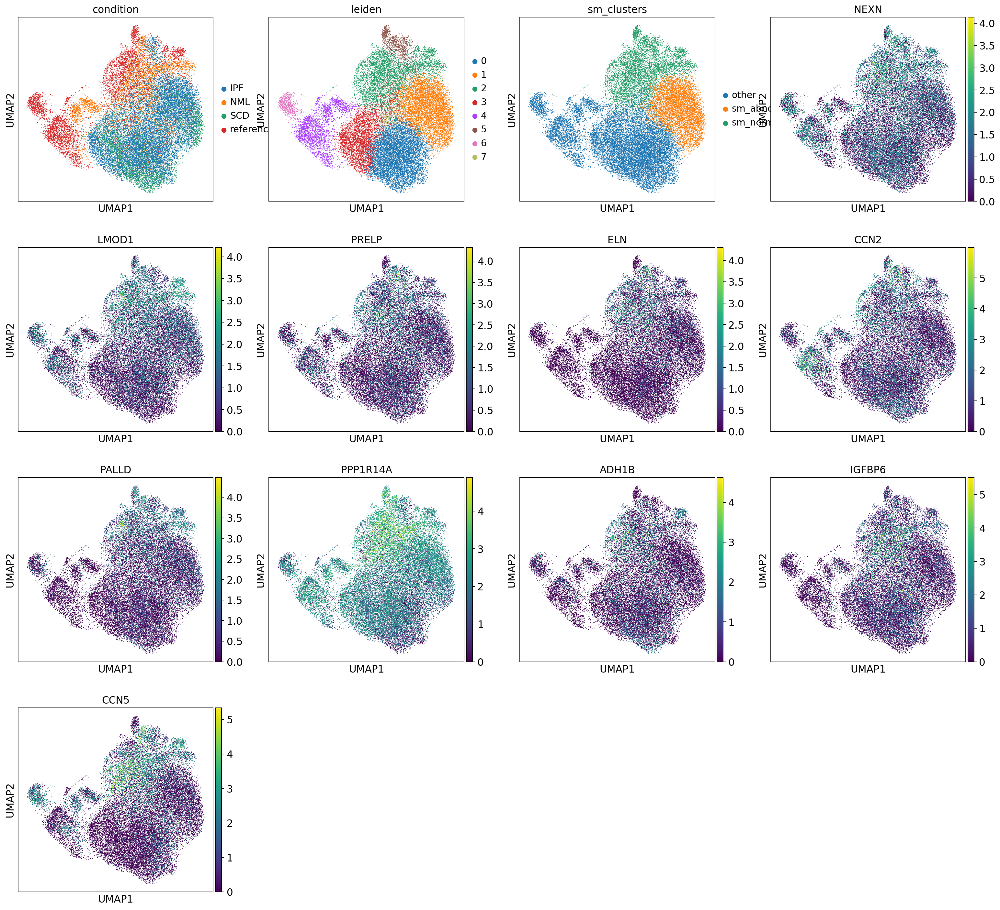

In [108]:
sc.pl.umap(
    adata_sm_dis,
    color=["condition", "leiden", "sm_clusters"]
    + degs_perictye_cluster_used_during_mapping.names[-10:].tolist(),
)

### Look at all fibroblasts, to make sure we're not just mis-annotating the smooth muscles and finding DEGs from other fibroblast types

In [110]:
fib_dis_emb = adata_emb[adata_emb.obs.leiden.isin([4, 10, 27, 32, 36]), :].copy()

In [111]:
fib_dis_emb.shape

(78118, 30)

In [112]:
fib_dis_emb.obs.condition.value_counts()

reference    25250
IPF          24926
NML          16682
SCD          11260
Name: condition, dtype: int64

In [113]:
for stat in [
    "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
]:
    fib_dis_emb.obs[stat] = np.nan
    healthy_idc = [
        idx
        for idx in fib_dis_emb.obs.index
        if idx in mapqc_results_healthy.adata.obs.index
    ]
    fib_dis_emb.obs.loc[healthy_idc, stat] = mapqc_results_healthy.adata.obs.loc[
        healthy_idc, stat
    ]
    disease_idc = [
        idx
        for idx in fib_dis_emb.obs.index
        if idx in mapqc_results_disease.adata.obs.index
    ]
    fib_dis_emb.obs.loc[disease_idc, stat] = mapqc_results_disease.adata.obs.loc[
        disease_idc, stat
    ]

In [114]:
sc.pp.neighbors(fib_dis_emb, n_neighbors=30)

In [115]:
sc.tl.umap(fib_dis_emb)

In [116]:
sc.tl.leiden(fib_dis_emb, resolution=0.5)

/tmp/ipykernel_2016428/4247297561.py:9: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


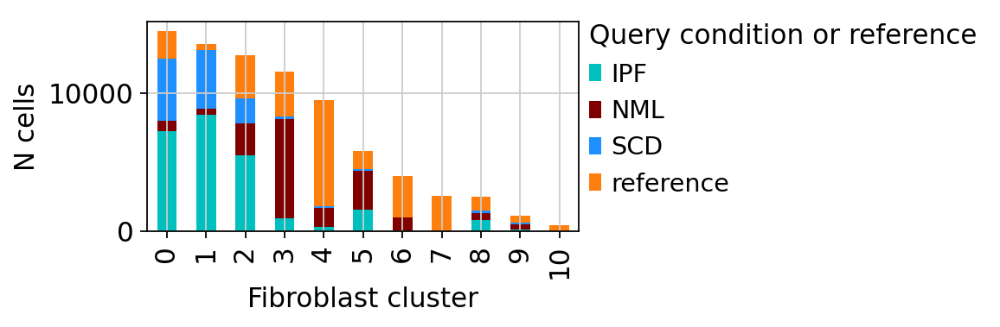

In [117]:
fig, ax = plt.subplots(figsize=(4, 2))
pd.crosstab(fib_dis_emb.obs.leiden, fib_dis_emb.obs.condition).plot(
    kind="bar", stacked="true", color=palette_condition, ax=ax
)
ax.set_ylabel("N cells")
ax.set_xlabel("Fibroblast cluster")
leg = plt.legend(loc=(1.0, 0.12), frameon=False, title="Query condition or reference")
leg._legend_box.align = "left"
plt.tight_layout()

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/

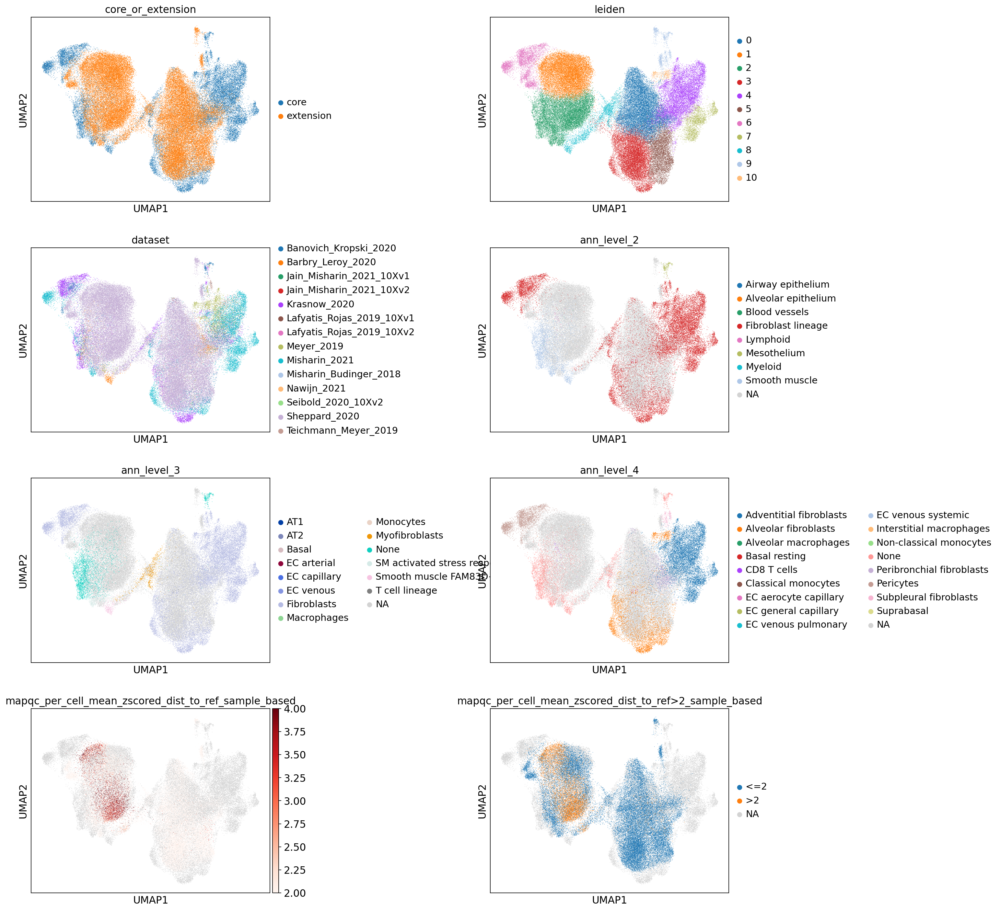

In [118]:
sc.pl.umap(
    fib_dis_emb,
    color=[
        "core_or_extension",
        "leiden",
        "dataset",
        "ann_level_2",
        "ann_level_3",
        "ann_level_4",
        "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
        "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
    ],
    ncols=2,
    wspace=0.75,
    vmin=2,
    vmax=4,
    cmap="Reds",
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


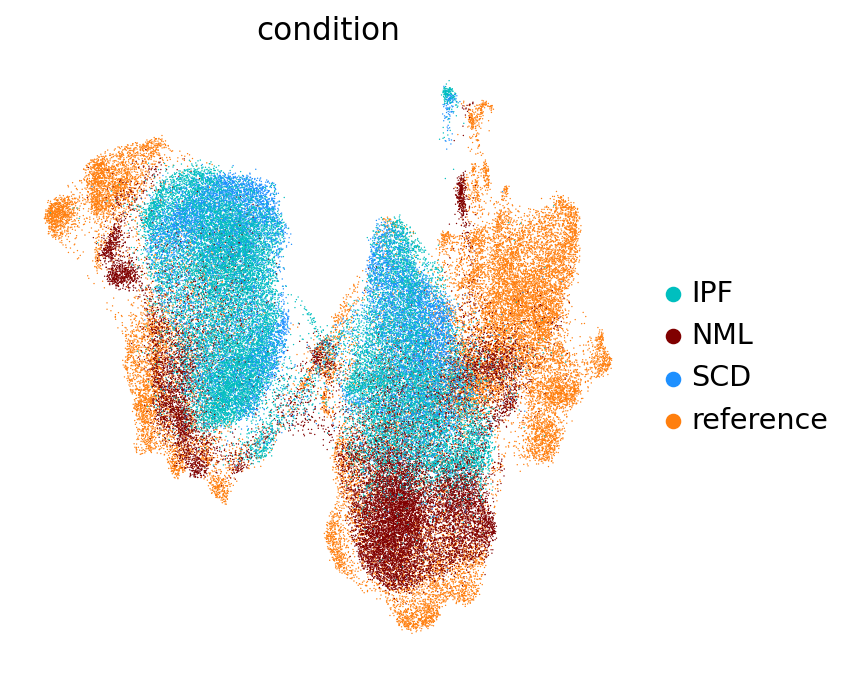

In [119]:
sc.pl.umap(fib_dis_emb, color="condition", palette=palette_condition, frameon=False)

In [120]:
fib_dis_emb.obs.index = [
    idx if ref_or_q == "core" else f"{idx}_tsukui"
    for idx, ref_or_q in zip(fib_dis_emb.obs.index, fib_dis_emb.obs.core_or_extension)
]

In [121]:
adata_fib_dis = adata_full[
    adata_full.obs.index.isin(fib_dis_emb.obs.index), :
].to_memory()

In [122]:
fib_dis_emb.shape

(78118, 30)

In [123]:
adata_fib_dis.shape

(78118, 59586)

In [124]:
sc.pp.filter_genes(adata_fib_dis, min_cells=5)

In [125]:
adata_fib_dis.shape

(78118, 23767)

In [126]:
adata_fib_dis.X[-10:, -10:].toarray()

array([[0.       , 0.       , 0.       , 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.       , 1.1973462],
       [0.       , 0.       , 0.       , 0.       , 1.3682551, 0.       ,
        0.       , 0.       , 0.       , 0.       ],
       [0.7554432, 0.       , 0.       , 0.       , 0.       , 0.       ,
        0.       , 0.7554432, 0.       , 0.       ],
       [0.       , 0.       , 0.       , 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.       , 0.       ],
       [0.       , 0.       , 0.       , 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.       , 0.       ],
       [0.       , 0.       , 0.       , 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.       , 0.       ],
       [0.       , 0.       , 0.       , 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.       , 0.       ],
       [1.3696746, 0.       , 0.       , 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.     

In [127]:
adata_fib_dis.uns["log1p"]["base"] = None

In [128]:
adata_fib_dis.obsm["X_umap"] = fib_dis_emb[adata_fib_dis.obs.index, :].obsm["X_umap"]

In [129]:
for cat in [
    "condition",
    "leiden",
    "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
]:
    adata_fib_dis.obs[cat] = fib_dis_emb.obs.loc[adata_fib_dis.obs.index, cat]

In [130]:
adata_fib_dis.obs.condition.value_counts()

reference    25250
IPF          24926
NML          16682
SCD          11260
Name: condition, dtype: int64

In [131]:
adata_fib_dis.var.index = adata_fib_dis.var.gene_symbol

plot pericyte and smooth muscle markers:

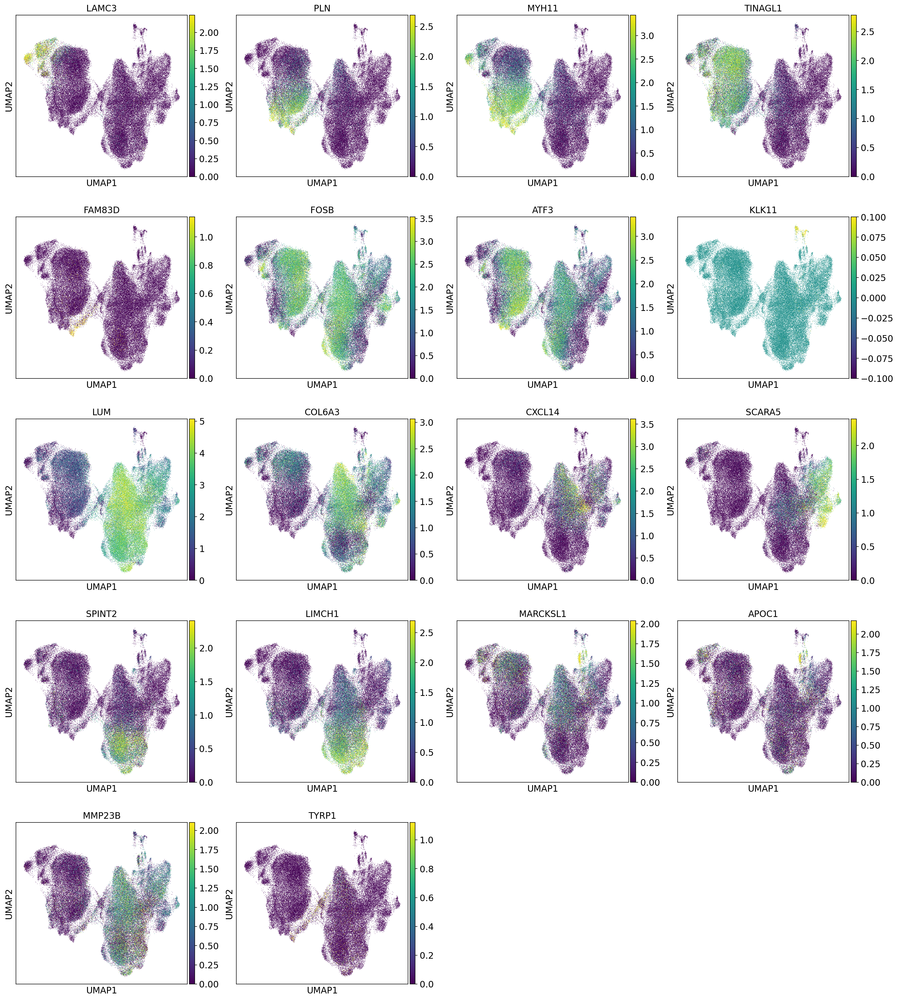

In [132]:
sc.pl.umap(
    adata_fib_dis,
    color=[
        "LAMC3",  # pericytes
        "PLN",  # smooth muscle, not pericytes
        "MYH11",  # smooth muscle, some in pericytes
        "TINAGL1",  # smooth muscle, some in pericytes
        "FAM83D",  # FAM83D+ sm
        "FOSB",  # SM stress
        "ATF3",  # SM stress
        "KLK11",  # mesothelium
        "LUM",  # fibroblasts
        "COL6A3",  # fibroblasts
        "CXCL14",  # peribronch. fibs.
        "SCARA5",  # adv. fibs.
        "SPINT2",  # alv. fibs.
        "LIMCH1",  # alv. fibs.
        "MARCKSL1",  # subpl. fibs.
        "APOC1",  # subpl. fibs.
        "MMP23B",  # subpl. fibs
        "TYRP1",  # myofibroblasts, some in sm FAM83D+
    ],
    vmax="p99",
)

In [133]:
sc.tl.rank_genes_groups(adata_fib_dis, groupby="leiden", groups=[1], reference="6")

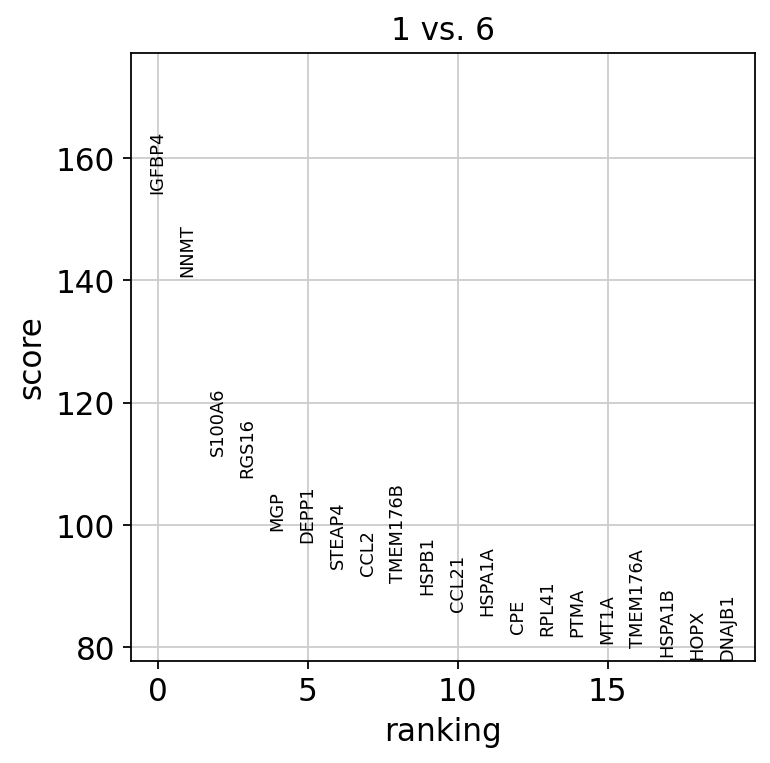

In [134]:
sc.pl.rank_genes_groups(adata_fib_dis)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


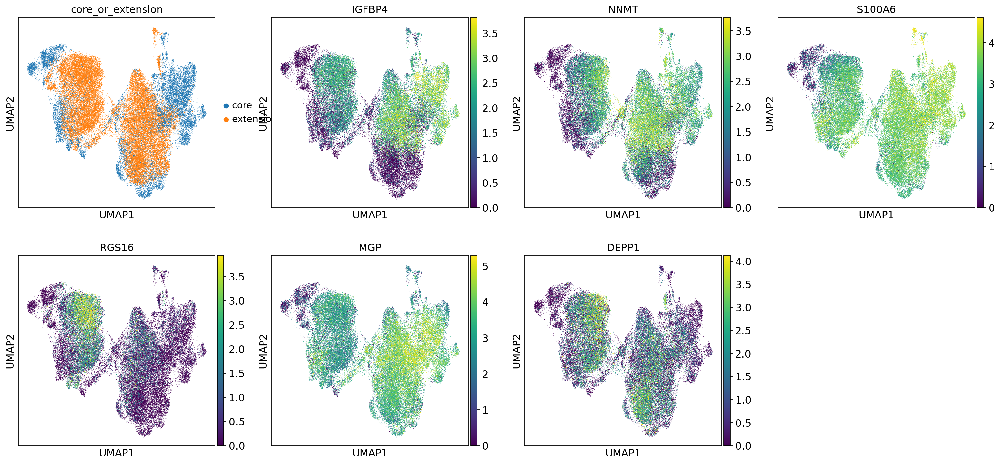

In [135]:
sc.pl.umap(
    adata_fib_dis,
    color=["core_or_extension", "IGFBP4", "NNMT", "S100A6", "RGS16", "MGP", "DEPP1"],
    vmax="p99",
)

In [136]:
fib_cell_counts = adata_fib_dis.obs.ann_level_3.value_counts()

In [137]:
fib_cell_counts

Fibroblasts                     48412
Unknown                         15365
None                             3183
SM activated stress response     1391
Myofibroblasts                   1187
Smooth muscle FAM83D+             376
T cell lineage                     74
Macrophages                        14
EC capillary                       12
Monocytes                          11
EC venous                           7
AT2                                 7
B cell lineage                      4
Basal                               3
Dendritic cells                     1
EC arterial                         1
AT1                                 1
Name: ann_level_3, dtype: int64

In [138]:
adata_fib_dis.obs["ann_level_3_cleaned"] = adata_fib_dis.obs.ann_level_3.map(
    {
        ct: (ct if ct_count > 50 else "Other")
        for ct, ct_count in zip(fib_cell_counts.index, fib_cell_counts.values)
    }
)

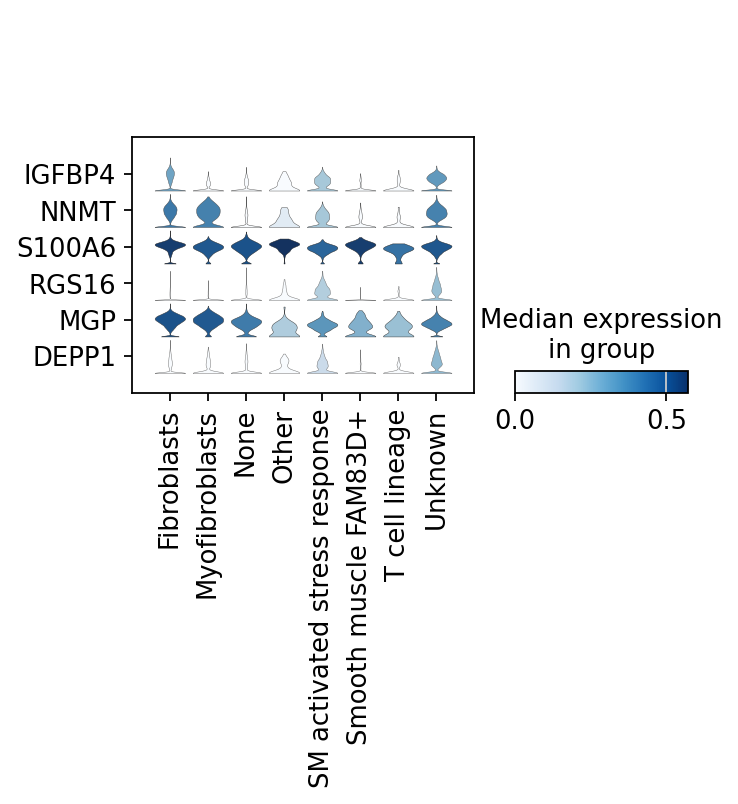

In [139]:
sc.pl.stacked_violin(
    adata_fib_dis,
    groupby="ann_level_3_cleaned",
    var_names=["IGFBP4", "NNMT", "S100A6", "RGS16", "MGP", "DEPP1"],
    swap_axes=True,
    standard_scale="var",
)

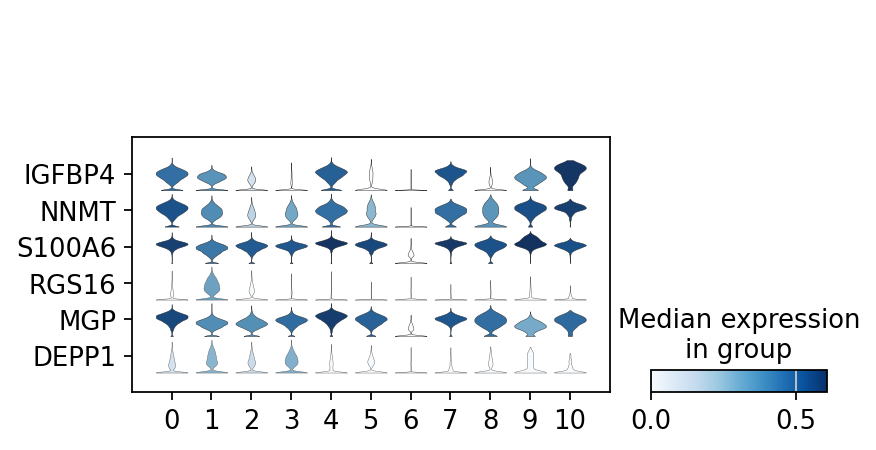

In [140]:
sc.pl.stacked_violin(
    adata_fib_dis,
    groupby="leiden",
    var_names=["IGFBP4", "NNMT", "S100A6", "RGS16", "MGP", "DEPP1"],
    swap_axes=True,
    standard_scale="var",
)

In [143]:
adata_fib_dis.obs["leiden_sm"] = np.nan
adata_fib_dis.obs.loc[adata_sm_dis.obs.index, "leiden_sm"] = adata_sm_dis.obs.leiden

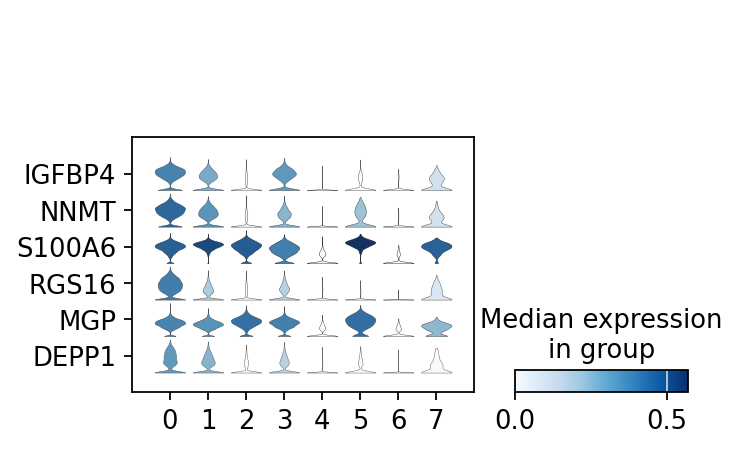

In [144]:
sc.pl.stacked_violin(
    adata_fib_dis,
    groupby="leiden_sm",
    var_names=["IGFBP4", "NNMT", "S100A6", "RGS16", "MGP", "DEPP1"],
    swap_axes=True,
    standard_scale="var",
)

check results from pericyte comparison:

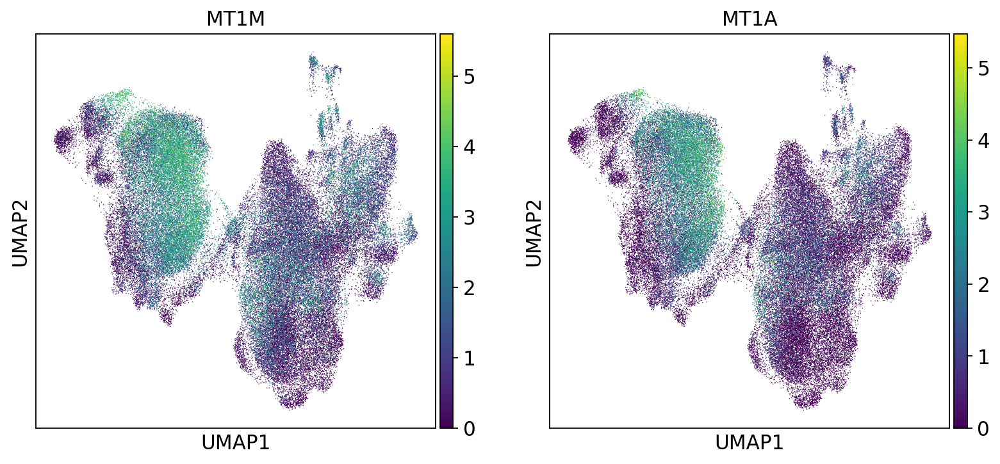

In [146]:
sc.pl.umap(
    adata_fib_dis,
    color=["MT1M", "MT1A"],
)

## B cell cluster:

In [149]:
bcell_emb = adata_emb[adata_emb.obs.leiden == 23, :].copy()

In [150]:
bcell_emb.shape

(5271, 30)

In [151]:
sc.pp.neighbors(bcell_emb, n_neighbors=30)
sc.tl.umap(bcell_emb)

In [154]:
for stat in [
    "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
]:
    bcell_emb.obs[stat] = np.nan
    healthy_idc = [
        idx
        for idx in bcell_emb.obs.index
        if idx in mapqc_results_healthy.adata.obs.index
    ]
    bcell_emb.obs.loc[healthy_idc, stat] = mapqc_results_healthy.adata.obs.loc[
        healthy_idc, stat
    ]
    disease_idc = [
        idx
        for idx in bcell_emb.obs.index
        if idx in mapqc_results_disease.adata.obs.index
    ]
    bcell_emb.obs.loc[disease_idc, stat] = mapqc_results_disease.adata.obs.loc[
        disease_idc, stat
    ]

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/

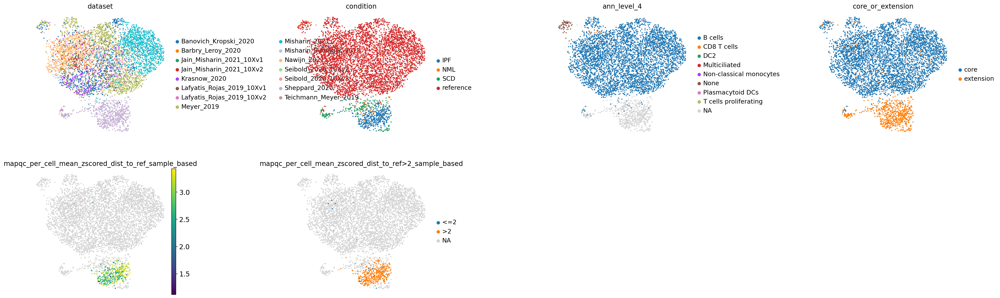

In [156]:
sc.pl.umap(
    bcell_emb,
    color=[
        "dataset",
        "condition",
        "ann_level_4",
        "core_or_extension",
        "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
        "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
    ],
    frameon=False,
    wspace=0.7,
    ncols=4,
)

In [159]:
bcell_emb.obs.index = [
    idx if ref_or_q == "core" else f"{idx}_tsukui"
    for idx, ref_or_q in zip(bcell_emb.obs.index, bcell_emb.obs.core_or_extension)
]

In [160]:
adata_bcell = adata_full[adata_full.obs.index.isin(bcell_emb.obs.index), :].to_memory()

In [161]:
bcell_emb.shape

(5271, 30)

In [162]:
adata_bcell.shape

(5271, 59586)

In [163]:
sc.pp.filter_genes(adata_bcell, min_cells=5)

In [164]:
adata_bcell.shape

(5271, 16363)

In [165]:
adata_bcell.X[-10:, -10:].toarray()

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.50829273, 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        1.1506395 , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.8693919 , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.       

In [166]:
adata_bcell.uns["log1p"]["base"] = None

In [167]:
adata_bcell.obsm["X_umap"] = bcell_emb[adata_bcell.obs.index, :].obsm["X_umap"]

In [168]:
for cat in [
    "condition",
    "leiden",
    "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
]:
    adata_bcell.obs[cat] = bcell_emb.obs.loc[adata_bcell.obs.index, cat]

In [169]:
adata_bcell.obs.condition.value_counts()

reference    4584
IPF           407
SCD           224
NML            56
Name: condition, dtype: int64

In [170]:
adata_bcell.var.index = adata_bcell.var.gene_symbol

In [171]:
sc.tl.rank_genes_groups(adata_bcell, groupby="condition")

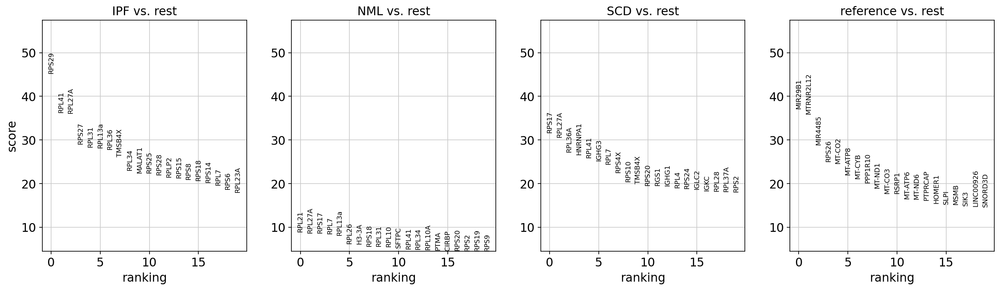

In [172]:
sc.pl.rank_genes_groups(adata_bcell)

## Macrophages:

In [176]:
macrophage_groups = [0, 8, 9, 14, 20, 22, 26, 28, 30, 31, 35, 37]

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


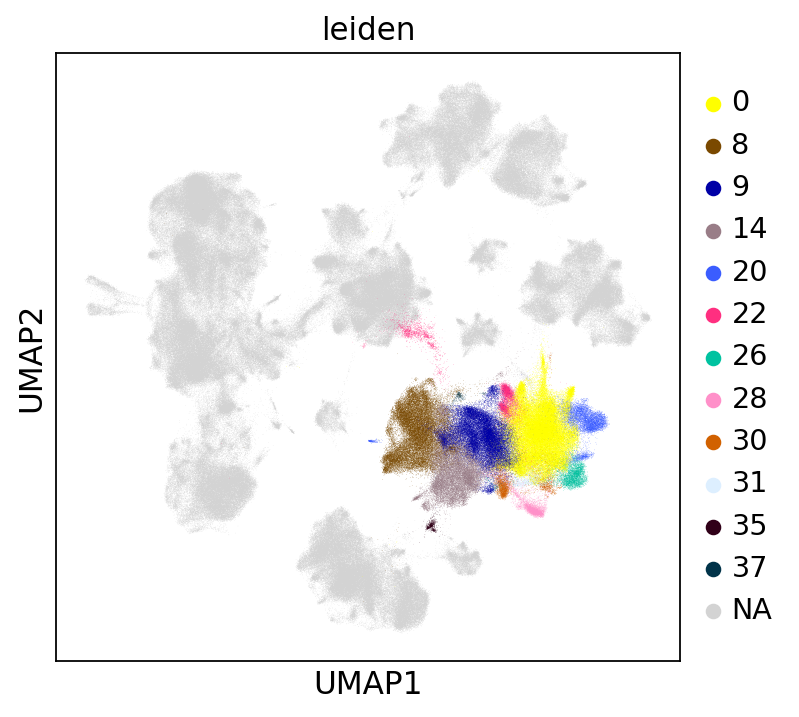

In [175]:
sc.pl.umap(
    adata_emb, color=["leiden"], groups=macrophage_groups
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


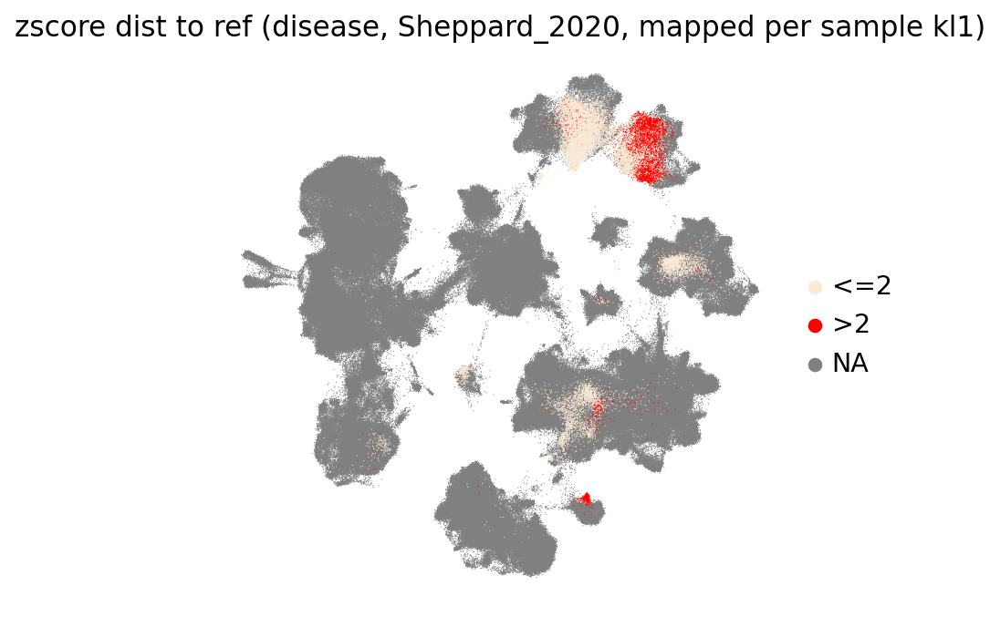

In [177]:
plotting.plot_umap_cell_level_results(
    mapqc_results_disease,
    color_by="zscore>2",
    size=1,
    title="zscore dist to ref (disease, Sheppard_2020, mapped per sample kl1)",
)

In [180]:
pd.crosstab(adata_emb.obs.leiden, adata_emb.obs.condition).loc[macrophage_groups, :]

condition,IPF,NML,SCD,reference
leiden,,,,
0,162,1634,361,56918
8,817,1865,212,25964
9,1521,1023,2700,22964
14,1372,995,714,16572
20,4,9,3,7224
22,2,90,8,6300
26,0,4,4,3997
28,1,11,3,3842
30,13,28,29,3461


In [181]:
mac_main_clusters = [0, 8, 9, 14]

In [183]:
adata_macs_emb = adata_emb[adata_emb.obs.leiden.isin(mac_main_clusters), :].copy()

In [187]:
for stat in [
    "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
]:
    adata_macs_emb.obs[stat] = np.nan
    healthy_idc = [
        idx
        for idx in adata_macs_emb.obs.index
        if idx in mapqc_results_healthy.adata.obs.index
    ]
    adata_macs_emb.obs.loc[healthy_idc, stat] = mapqc_results_healthy.adata.obs.loc[
        healthy_idc, stat
    ]
    disease_idc = [
        idx
        for idx in adata_macs_emb.obs.index
        if idx in mapqc_results_disease.adata.obs.index
    ]
    adata_macs_emb.obs.loc[disease_idc, stat] = mapqc_results_disease.adata.obs.loc[
        disease_idc, stat
    ]

In [188]:
pd.crosstab(
    adata_macs_emb.obs.leiden,
    adata_macs_emb.obs["mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based"],
)

mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based,<=2,>2
leiden,,
0,1122,33
8,1566,253
9,1885,150
14,1871,36


In [189]:
sc.pp.neighbors(adata_macs_emb, n_neighbors=30)
sc.tl.umap(adata_macs_emb)

In [ ]:
sc.tl.leiden(adata_macs_emb, key_added="leiden_macs", resolution=0.3)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/

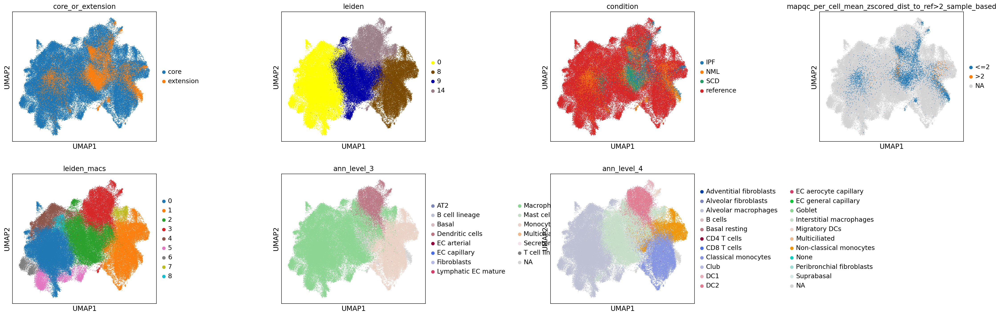

In [218]:
sc.pl.umap(
    adata_macs_emb,
    color=[
        "core_or_extension",
        "leiden",
        "condition",
        "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
        "leiden_macs",
        "ann_level_3",
        "ann_level_4",
    ],
    wspace=0.7,
    size=4,
)

In [191]:
adata_macs_emb.obs.index = [
    idx if ref_or_q == "core" else f"{idx}_tsukui"
    for idx, ref_or_q in zip(
        adata_macs_emb.obs.index, adata_macs_emb.obs.core_or_extension
    )
]

In [192]:
adata_macs = adata_full[
    adata_full.obs.index.isin(adata_macs_emb.obs.index), :
].to_memory()

In [193]:
adata_macs_emb.shape

(135794, 30)

In [194]:
adata_macs.shape

(135794, 59586)

In [195]:
sc.pp.filter_genes(adata_macs, min_cells=5)

In [196]:
adata_macs.shape

(135794, 23985)

In [197]:
adata_macs.X[-10:, -10:].toarray()

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [1.2526702 , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.54890573, 0.        , 0.        , 0.        , 0.        ,
        0.54890573, 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [1.6310432 , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.       

In [198]:
adata_macs.uns["log1p"]["base"] = None

In [199]:
adata_macs.obsm["X_umap"] = adata_macs_emb[adata_macs.obs.index, :].obsm["X_umap"]

In [225]:
for cat in [
    "condition",
    "leiden",
    "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
    "leiden_macs",
]:
    adata_macs.obs[cat] = adata_macs_emb.obs.loc[adata_macs.obs.index, cat]

In [201]:
adata_macs.obs.condition.value_counts()

reference    122418
NML            5517
SCD            3987
IPF            3872
Name: condition, dtype: int64

In [202]:
adata_macs.var.index = adata_macs.var.gene_symbol

check which cluster has the most high-dist cells for IPF:

In [224]:
pd.crosstab(
    adata_macs_emb.obs.loc[adata_macs_emb.obs.condition == "IPF", "leiden_macs"],
    adata_macs_emb.obs.loc[
        adata_macs_emb.obs.condition == "IPF",
        "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
    ],
)

mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based,<=2,>2
leiden_macs,,
0,49,30
1,139,4
2,1397,153
3,1011,35
7,1,0


do dea analysis on that cluster

In [229]:
adata_macs_cl2 = adata_macs[adata_macs.obs.leiden_macs == "2", :].copy()

In [231]:
sc.pp.filter_genes(adata_macs_cl2, min_cells=10)

In [232]:
adata_macs_cl2.shape

(27607, 18277)

In [233]:
adata_macs_cl2.obs["query_dist_from_ref"] = "reference_or_mixing"
adata_macs_cl2.obs.loc[
    adata_macs_cl2.obs["mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based"]
    == ">2",
    "query_dist_from_ref",
] = "nonmixing_query"

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


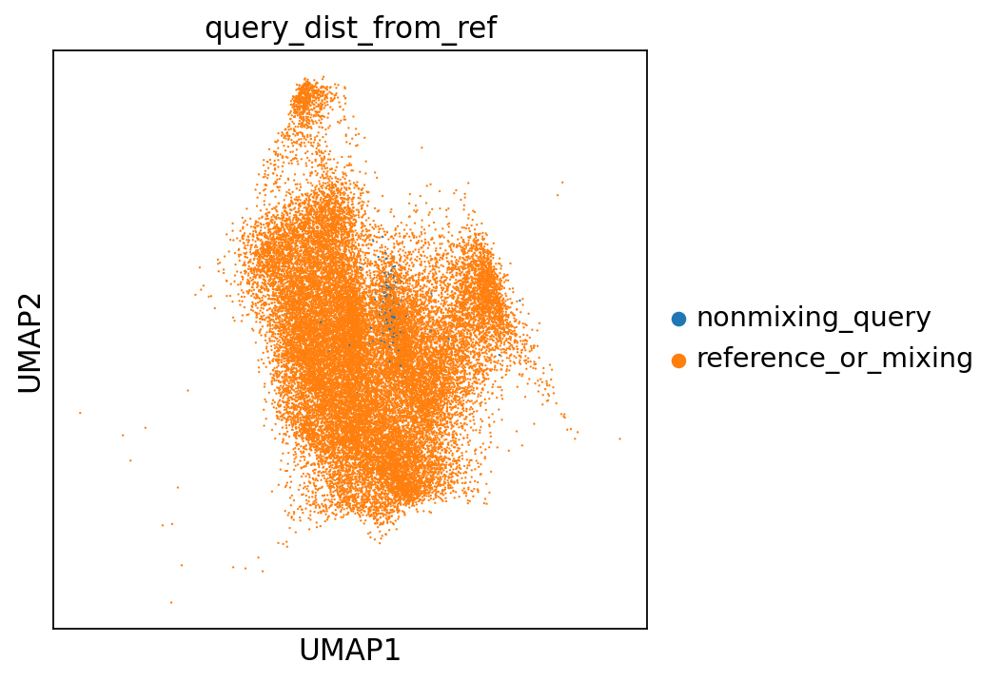

In [234]:
sc.pl.umap(adata_macs_cl2, color="query_dist_from_ref")

In [235]:
sc.tl.rank_genes_groups(adata_macs_cl2, groupby="query_dist_from_ref")

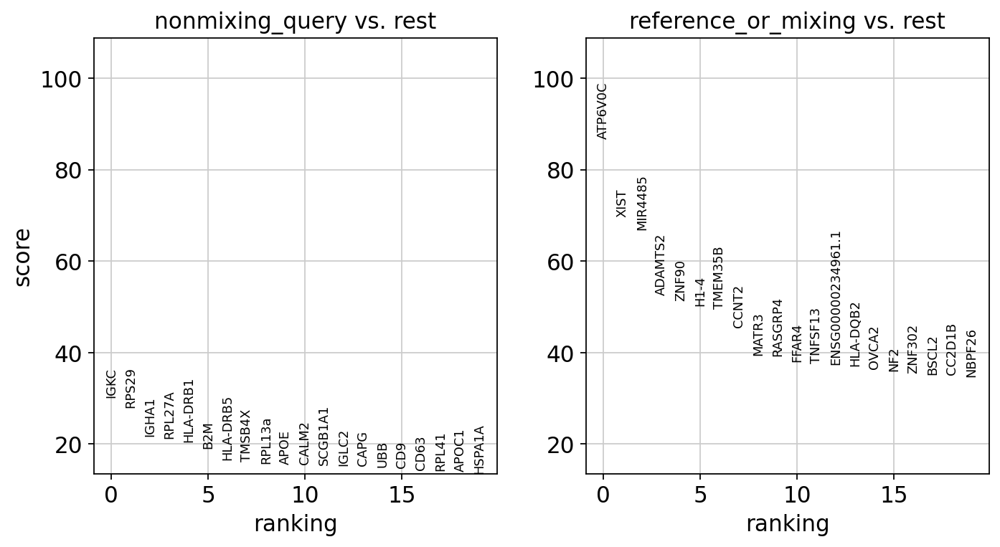

In [236]:
sc.pl.rank_genes_groups(adata_macs_cl2)